# Pemetaan Ketimpangan Akses Air Minum Layak dan Sanitasi Layak di Indonesia

**Oleh: Kelompok 2**

| Nama | NIM |
|---|---|
| Rava Dwi Andika | 25031554039 |
| Welfee Putri Sukardi | 25031554205 |

**Proyek Akhir Data Wrangling**  
Semester Gasal 2026/2027

## 1. Latar Belakang

Air minum layak dan sanitasi layak merupakan layanan dasar yang berhubungan dengan kualitas hidup masyarakat. Akses terhadap kedua layanan tersebut dapat berbeda antarwilayah. Karena itu, analisis kewilayahan diperlukan untuk menggambarkan daerah yang menghadapi kekurangan akses relatif lebih besar.

Proyek ini mengolah data persentase akses air minum layak dan sanitasi layak di Indonesia. Analisis dilakukan pada tingkat provinsi untuk menentukan provinsi dengan Combined Deprivation Index (CDI) tertinggi, kemudian dilanjutkan dengan analisis kabupaten/kota di provinsi tersebut.

## 2. Tujuan

1. Memeriksa dan membersihkan data akses air minum layak dan sanitasi layak.
2. Menghitung deprivation masing-masing indikator dan Combined Deprivation Index (CDI).
3. Menentukan isu dominan antara air minum dan sanitasi pada setiap wilayah.
4. Mengidentifikasi provinsi dengan CDI tertinggi.
5. Menganalisis kabupaten/kota pada provinsi terpilih dan menyajikan hasilnya dalam peta.

## 3. Ruang Lingkup

Indikator utama yang digunakan dalam proyek ini hanya:

- Persentase rumah tangga dengan akses terhadap sumber air minum layak.
- Persentase rumah tangga dengan akses terhadap sanitasi layak.

Deprivation air minum dihitung sebagai 100 dikurangi persentase akses air minum layak. Deprivation sanitasi dihitung sebagai 100 dikurangi persentase akses sanitasi layak. CDI dihitung sebagai rata-rata kedua deprivation, hanya jika kedua indikator tersedia.

Analisis ini bersifat deskriptif. CDI memberikan bobot yang sama pada deprivation air minum dan sanitasi, serta bukan ukuran resmi kemiskinan multidimensi.

## 4. Sumber Data

Analisis ini mengintegrasikan data dari tiga sumber: BPS, Badan Informasi Geospasial (BIG), dan Kementerian Dalam Negeri. Data indikator menggunakan tahun 2025.

| Instansi | Data yang digunakan | File lokal | Asal data | Tahun/edisi |
|---|---|---|---|---|
| Badan Pusat Statistik (BPS) | Persentase akses air minum layak tingkat kabupaten/kota | `data/raw/Persentase Rumah Tangga yang Memiliki Akses terhadap Sumber Air Minum Layak menurut Kabupaten_Kota, 2025.csv` | BPS | 2025 |
| Badan Pusat Statistik (BPS) | Persentase akses sanitasi layak tingkat kabupaten/kota | `data/raw/6.2.1_ Persentase rumah tangga yang memiliki akses terhadap sanitasi layak menurut kabupaten_kota, 2025.csv` | BPS | 2025 |
| Badan Pusat Statistik (BPS) | Persentase akses air minum dan sanitasi tingkat provinsi | File Excel indikator provinsi di `data/raw/` | BPS | 2025 |
| Badan Informasi Geospasial (BIG) | Batas administrasi kabupaten/kota | `data/raw/batas_kabupaten_kota.geojson` | BIG | 2025 |
| Kementerian Dalam Negeri | Kode dan nama wilayah administrasi | `data/raw/KODE-WILAYAH-KEPMENDAGRI-2025.xlsx` | Kemendagri | 2025 |

GeoJSON telah tersedia secara lokal dan dibaca dari folder `data/raw/`; notebook tidak mengunduh ulang batas wilayah. File sumber tidak diubah selama analisis.

## 5. Struktur Folder dan Lokasi File

Seluruh file sumber berada di folder `data/raw/`. Hasil analisis akan disimpan terpisah di folder `outputs/`.

Struktur folder yang digunakan:

```text
project-data-wrangling/
├── .gitattributes
├── .gitignore
├── README.md
├── requirements.txt
├── data/
│   └── raw/
│       ├── 6.2.1_ Persentase rumah tangga yang memiliki akses terhadap sanitasi layak menurut kabupaten_kota, 2025.csv
│       ├── batas_kabupaten_kota.geojson
│       ├── KODE-WILAYAH-KEPMENDAGRI-2025.xlsx
│       ├── Persentase Rumah Tangga yang Memiliki Akses terhadap Sanitasi Layak Menurut Provinsi dan Klasifikasi Desa, 2025.xlsx
│       ├── Persentase Rumah Tangga yang Memiliki Akses terhadap Sumber Air Minum Layak Menurut Provinsi dan Klasifikasi Desa, 2025.xlsx
│       └── Persentase Rumah Tangga yang Memiliki Akses terhadap Sumber Air Minum Layak menurut Kabupaten_Kota, 2025.csv
├── notebooks/
│   ├── notebook.ipynb
│   └── scrap-geojson.ipynb
└── outputs/
    ├── analisis_kabupaten_kota_95.csv
    ├── clean_data_kabupaten_kota.csv
    ├── clustering_kmeans_deprivation.png
    ├── data_peta_95.csv
    ├── deprivation_dan_CDI_kabkota_terpilih.png
    ├── evaluasi_jumlah_klaster.csv
    ├── korelasi_air_sanitasi.png
    ├── peta_CDI_95.html
    ├── peta_kategori_dominan_95.html
    ├── ranking_CDI_provinsi.csv
    ├── ringkasan_klaster.csv
    ├── scatter_deprivation_nasional.png
    └── top15_provinsi_CDI_2025.png
```


In [11]:
from pathlib import Path

# Cari folder proyek dari lokasi kerja notebook atau folder induknya.
kandidat_folder = [Path.cwd(), *Path.cwd().parents]

PROJECT_DIR = next(
    (
        folder
        for folder in kandidat_folder
        if (folder / "data" / "raw").is_dir()
    ),
    None
)

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Folder data/raw tidak ditemukan. "
        "Jalankan notebook dari dalam folder proyek yang berisi data/raw."
    )

RAW_DIR = PROJECT_DIR / "data" / "raw"
REFERENCE_DIR = PROJECT_DIR / "data" / "reference"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# File indikator kabupaten/kota
AIR_KAB_PATH = RAW_DIR / (
    "Persentase Rumah Tangga yang Memiliki Akses terhadap "
    "Sumber Air Minum Layak menurut Kabupaten_Kota, 2025.csv"
)

SANITASI_KAB_PATH = RAW_DIR / (
    "6.2.1_ Persentase rumah tangga yang memiliki akses terhadap "
    "sanitasi layak menurut kabupaten_kota, 2025.csv"
)

# File indikator provinsi
AIR_PROV_PATH = RAW_DIR / (
    "Persentase Rumah Tangga yang Memiliki Akses terhadap "
    "Sumber Air Minum Layak Menurut Provinsi dan Klasifikasi Desa, 2025.xlsx"
)

SANITASI_PROV_PATH = RAW_DIR / (
    "Persentase Rumah Tangga yang Memiliki Akses terhadap "
    "Sanitasi Layak Menurut Provinsi dan Klasifikasi Desa, 2025.xlsx"
)

KODE_WILAYAH_PATH = RAW_DIR / "KODE-WILAYAH-KEPMENDAGRI-2025.xlsx"
GEOJSON_PATH = RAW_DIR / "batas_kabupaten_kota.geojson"

SOURCE_PATHS = {
    "Air minum kabupaten/kota": AIR_KAB_PATH,
    "Sanitasi kabupaten/kota": SANITASI_KAB_PATH,
    "Air minum provinsi": AIR_PROV_PATH,
    "Sanitasi provinsi": SANITASI_PROV_PATH,
    "Kode wilayah Kemendagri": KODE_WILAYAH_PATH,
    "Batas kabupaten/kota BIG": GEOJSON_PATH,
}

# Pastikan semua file yang dibutuhkan tersedia.
file_tidak_ditemukan = [
    nama for nama, path in SOURCE_PATHS.items()
    if not path.is_file()
]

if file_tidak_ditemukan:
    raise FileNotFoundError(
        "File berikut tidak ditemukan di data/raw:\n- "
        + "\n- ".join(file_tidak_ditemukan)
    )

print("Folder proyek:", PROJECT_DIR.resolve())
print("Folder output:", OUTPUT_DIR.resolve())
print("Semua file sumber ditemukan.")

Folder proyek: D:\Kuliah\Data Wrangling\Project
Folder output: D:\Kuliah\Data Wrangling\Project\outputs
Semua file sumber ditemukan.


## 6. Membaca Data Indikator

Pada tahap ini, file indikator dibaca ke dalam DataFrame pandas. DataFrame adalah tabel di Python yang memudahkan kita memeriksa dan mengolah baris serta kolom.

Data dibaca sebagai teks terlebih dahulu agar kode wilayah tidak kehilangan angka nol di depannya. Pembersihan dan konversi ke tipe data numerik akan dilakukan setelah nama dan format kolom diperiksa.

In [12]:
import pandas as pd
import numpy as np

# Baca file CSV sebagai teks
air_kab_raw = pd.read_csv(
    AIR_KAB_PATH,
    dtype="string"
)

sanitasi_kab_raw = pd.read_csv(
    SANITASI_KAB_PATH,
    dtype="string"
)

print("Data air minum kabupaten/kota:", air_kab_raw.shape)
print("Data sanitasi kabupaten/kota:", sanitasi_kab_raw.shape)

Data air minum kabupaten/kota: (516, 2)
Data sanitasi kabupaten/kota: (516, 2)


In [13]:
# Baca sheet pertama dari file Excel.
# Jika tabel berada di sheet lain, ubah sheet_name sesuai hasil pemeriksaan.
air_prov_raw = pd.read_excel(
    AIR_PROV_PATH,
    sheet_name=0,
    dtype="string"
)

sanitasi_prov_raw = pd.read_excel(
    SANITASI_PROV_PATH,
    sheet_name=0,
    dtype="string"
)

kode_wilayah_raw = pd.read_excel(
    KODE_WILAYAH_PATH,
    sheet_name=0,
    dtype="string"
)

print("Data air minum provinsi:", air_prov_raw.shape)
print("Data sanitasi provinsi:", sanitasi_prov_raw.shape)
print("Referensi kode wilayah:", kode_wilayah_raw.shape)

Data air minum provinsi: (42, 4)
Data sanitasi provinsi: (42, 4)
Referensi kode wilayah: (83762, 9)


In [14]:
# Tampilkan nama kolom dan contoh baris dari setiap tabel
data_sources = {
    "Air minum kabupaten/kota": air_kab_raw,
    "Sanitasi kabupaten/kota": sanitasi_kab_raw,
    "Air minum provinsi": air_prov_raw,
    "Sanitasi provinsi": sanitasi_prov_raw,
    "Kode wilayah Kepmendagri": kode_wilayah_raw,
}

for nama, data in data_sources.items():
    print(f"\n{'=' * 70}")
    print(nama)
    print("Kolom:", data.columns.tolist())
    display(data.head())


Air minum kabupaten/kota
Kolom: ['Kabupaten/Kota', 'Unnamed: 1']


,Kabupaten/Kota,Unnamed: 1
0,<NA>,Persentase Rumah Tangga yang Memiliki Akses te...
1,<NA>,2025
2,Simeulue,85.13
3,Aceh Singkil,81.35
4,Aceh Selatan,90.47



Sanitasi kabupaten/kota
Kolom: ['Kabupaten/Kota', 'Unnamed: 1']


,Kabupaten/Kota,Unnamed: 1
0,<NA>,6.2.1* Persentase rumah tangga yang memiliki a...
1,<NA>,2025
2,Simeulue,78.94
3,Aceh Singkil,67.35
4,Aceh Selatan,78.42



Air minum provinsi
Kolom: ['38 Provinsi', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3']


,38 Provinsi,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,<NA>,Persentase Rumah Tangga yang Memiliki Akses te...,<NA>,<NA>
1,<NA>,Perkotaan,Perdesaan,Perkotaan+Perdesaan
2,<NA>,2025,2025,2025
3,ACEH,95.57,90.11,92.06
4,SUMATERA UTARA,96.22,89.17,93.24



Sanitasi provinsi
Kolom: ['38 Provinsi', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3']


,38 Provinsi,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,<NA>,Persentase Rumah Tangga yang Memiliki Akses te...,<NA>,<NA>
1,<NA>,Perkotaan,Perdesaan,Perkotaan+Perdesaan
2,<NA>,2025,2025,2025
3,ACEH,87.89,79.06,82.21
4,SUMATERA UTARA,91.28,82.27,87.47



Kode wilayah Kepmendagri
Kolom: ['KODE DESA', 'NAMA KELURAHAN/DESA/DESA ADAT', 'KODE KECAMATAN', 'NAMA KECAMATAN', 'KODE KABUPATEN', 'NAMA KABUPATEN', 'KODE PROVINSI', 'NAMA PROVINSI', 'TIPE DESA(KELURAHAN, DESA, DESA ADAT)']


,KODE DESA,NAMA KELURAHAN/DESA/DESA ADAT,KODE KECAMATAN,NAMA KECAMATAN,KODE KABUPATEN,NAMA KABUPATEN,KODE PROVINSI,NAMA PROVINSI,"TIPE DESA(KELURAHAN, DESA, DESA ADAT)"
0,11.01.01.2001,Keude Bakongan,11.01.01,Bakongan,11.01,Kabupaten Aceh Selatan,11,Aceh,DESA
1,11.01.01.2002,Ujong Mangki,11.01.01,Bakongan,11.01,Kabupaten Aceh Selatan,11,Aceh,DESA
2,11.01.01.2003,Ujong Padang,11.01.01,Bakongan,11.01,Kabupaten Aceh Selatan,11,Aceh,DESA
3,11.01.01.2004,Gampong Drien,11.01.01,Bakongan,11.01,Kabupaten Aceh Selatan,11,Aceh,DESA
4,11.01.01.2015,Darul Ikhsan,11.01.01,Bakongan,11.01,Kabupaten Aceh Selatan,11,Aceh,DESA


## 7. Menyiapkan Tabel Indikator

File CSV kabupaten/kota memiliki dua baris keterangan di awal. File Excel provinsi memiliki tiga baris keterangan, termasuk pemisahan nilai perkotaan, perdesaan, dan gabungan.

Pada tahap ini, baris keterangan dipisahkan dari tabel analisis. Untuk data provinsi, nilai yang digunakan adalah kolom **Perkotaan+Perdesaan**, karena analisis membandingkan total setiap provinsi.

Tabel mentah tetap disimpan dalam variabel `*_raw` agar dapat dibandingkan dengan hasil penyiapan.

In [15]:
def ubah_ke_angka_persen(kolom):
    """
    Mengubah nilai persentase menjadi angka.
    Tanda '-', sel kosong, dan teks yang bukan angka menjadi missing value.
    """
    teks = kolom.astype("string").str.strip()

    # Perlakukan tanda minus dan teks kosong sebagai nilai hilang
    teks = teks.replace({
        "-": pd.NA,
        "": pd.NA,
        "NA": pd.NA,
        "N/A": pd.NA
    })

    # Ubah koma desimal menjadi titik jika ada
    teks = teks.str.replace(",", ".", regex=False)

    return pd.to_numeric(teks, errors="coerce")

In [16]:
# Dua baris pertama adalah judul indikator dan tahun, bukan data wilayah.
air_kab = air_kab_raw.iloc[2:, :2].copy()
sanitasi_kab = sanitasi_kab_raw.iloc[2:, :2].copy()

# Beri nama kolom yang seragam agar mudah digabungkan nanti.
air_kab.columns = ["nama_wilayah", "akses_air"]
sanitasi_kab.columns = ["nama_wilayah", "akses_sanitasi"]

# Bersihkan spasi di awal dan akhir nama wilayah.
for data in [air_kab, sanitasi_kab]:
    data["nama_wilayah"] = data["nama_wilayah"].astype("string").str.strip()

# Ubah persentase menjadi numerik.
air_kab["akses_air"] = ubah_ke_angka_persen(air_kab["akses_air"])
sanitasi_kab["akses_sanitasi"] = ubah_ke_angka_persen(
    sanitasi_kab["akses_sanitasi"]
)

# Hilangkan baris yang tidak memiliki nama wilayah.
air_kab = air_kab.dropna(subset=["nama_wilayah"]).reset_index(drop=True)
sanitasi_kab = sanitasi_kab.dropna(subset=["nama_wilayah"]).reset_index(drop=True)

print("Baris data air kabupaten/kota:", len(air_kab))
print("Baris data sanitasi kabupaten/kota:", len(sanitasi_kab))

display(air_kab.head())
display(sanitasi_kab.head())

Baris data air kabupaten/kota: 514
Baris data sanitasi kabupaten/kota: 514


,nama_wilayah,akses_air
0,Simeulue,85.13
1,Aceh Singkil,81.35
2,Aceh Selatan,90.47
3,Aceh Tenggara,96.24
4,Aceh Timur,86.62


,nama_wilayah,akses_sanitasi
0,Simeulue,78.94
1,Aceh Singkil,67.35
2,Aceh Selatan,78.42
3,Aceh Tenggara,66.67
4,Aceh Timur,75.14


In [17]:
# Baris data provinsi dimulai dari indeks 3.
# Kolom 0 berisi nama provinsi.
# Kolom 3 berisi nilai Perkotaan+Perdesaan.
air_prov = air_prov_raw.iloc[3:, [0, 3]].copy()
sanitasi_prov = sanitasi_prov_raw.iloc[3:, [0, 3]].copy()

air_prov.columns = ["nama_provinsi", "akses_air"]
sanitasi_prov.columns = ["nama_provinsi", "akses_sanitasi"]

for data in [air_prov, sanitasi_prov]:
    data["nama_provinsi"] = (
        data["nama_provinsi"]
        .astype("string")
        .str.strip()
    )

air_prov["akses_air"] = ubah_ke_angka_persen(air_prov["akses_air"])
sanitasi_prov["akses_sanitasi"] = ubah_ke_angka_persen(
    sanitasi_prov["akses_sanitasi"]
)

air_prov = air_prov.dropna(subset=["nama_provinsi"]).reset_index(drop=True)
sanitasi_prov = sanitasi_prov.dropna(
    subset=["nama_provinsi"]
).reset_index(drop=True)

print("Baris data air provinsi:", len(air_prov))
print("Baris data sanitasi provinsi:", len(sanitasi_prov))

display(air_prov.head())
display(sanitasi_prov.head())

Baris data air provinsi: 39
Baris data sanitasi provinsi: 39


,nama_provinsi,akses_air
0,ACEH,92.06
1,SUMATERA UTARA,93.24
2,SUMATERA BARAT,87.26
3,RIAU,92.17
4,JAMBI,82.46


,nama_provinsi,akses_sanitasi
0,ACEH,82.21
1,SUMATERA UTARA,87.47
2,SUMATERA BARAT,74.59
3,RIAU,91.21
4,JAMBI,85.88


In [18]:
print("Rentang akses air kabupaten/kota:")
display(air_kab["akses_air"].describe())

print("Rentang akses sanitasi kabupaten/kota:")
display(sanitasi_kab["akses_sanitasi"].describe())

print("Rentang akses air provinsi:")
display(air_prov["akses_air"].describe())

print("Rentang akses sanitasi provinsi:")
display(sanitasi_prov["akses_sanitasi"].describe())

Rentang akses air kabupaten/kota:


count       513.0
mean     88.34768
std      13.27202
min         14.93
25%         84.79
50%         92.62
75%         97.53
max         100.0
Name: akses_air, dtype: Float64

Rentang akses sanitasi kabupaten/kota:


count        513.0
mean     82.933099
std      16.778332
min           1.13
25%          77.86
50%          88.19
75%          93.47
max          100.0
Name: akses_sanitasi, dtype: Float64

Rentang akses air provinsi:


count         39.0
mean     87.751795
std      11.496206
min          32.89
25%         83.375
50%          90.01
75%         94.885
max          99.98
Name: akses_air, dtype: Float64

Rentang akses sanitasi provinsi:


count         39.0
mean         83.02
std      14.767105
min          16.34
25%         81.505
50%          85.98
75%          89.54
max           98.2
Name: akses_sanitasi, dtype: Float64

## 8. Membaca Batas Administrasi Kabupaten/Kota

File GeoJSON batas kabupaten/kota yang telah diunduh dibaca dari folder `data/raw/`. Pemeriksaan awal mencakup jumlah fitur, sistem koordinat, geometri kosong, dan nama atribut.

Pada tahap ini geometri belum digabungkan dengan data indikator. Kita perlu mengetahui struktur dan atribut GeoJSON terlebih dahulu agar proses pencocokan wilayah dapat dilakukan dengan benar.

In [19]:
import geopandas as gpd

if not GEOJSON_PATH.exists():
    raise FileNotFoundError(
        f"File GeoJSON tidak ditemukan: {GEOJSON_PATH.resolve()}"
    )

batas_raw = gpd.read_file(GEOJSON_PATH)

print("Jumlah fitur:", len(batas_raw))
print("CRS:", batas_raw.crs)
print("Jumlah kolom:", len(batas_raw.columns))
print("Kolom atribut:")
print(batas_raw.columns.tolist())

Jumlah fitur: 548
CRS: EPSG:4326
Jumlah kolom: 27
Kolom atribut:
['OBJECTID', 'NAMOBJ', 'FCODE', 'REMARK', 'METADATA', 'SRS_ID', 'KDBBPS', 'KDCBPS', 'KDCPUM', 'KDEBPS', 'KDEPUM', 'KDPBPS', 'KDPKAB', 'KDPPUM', 'LUASWH', 'TIPADM', 'WADMKC', 'WADMKD', 'WADMKK', 'WADMPR', 'WIADKC', 'WIADKK', 'WIADPR', 'WIADKD', 'SHAPE_Length', 'SHAPE_Area', 'geometry']


In [20]:
# Periksa geometri kosong dan geometri yang tidak valid.
print("Geometri kosong:", batas_raw.geometry.isna().sum())
print("Geometri kosong/bentuk kosong:", batas_raw.geometry.is_empty.sum())
print("Geometri tidak valid:", (~batas_raw.geometry.is_valid).sum())
print("Jumlah CRS yang tercatat:", batas_raw.crs)

Geometri kosong: 0
Geometri kosong/bentuk kosong: 0
Geometri tidak valid: 5
Jumlah CRS yang tercatat: EPSG:4326


### Penjelasan pemeriksaan GeoJSON

- **Fitur** adalah objek wilayah yang tersimpan dalam GeoJSON.
- **CRS** menjelaskan sistem koordinat geometri. Folium membutuhkan koordinat geografis WGS 84, yaitu EPSG:4326; jika CRS berbeda, geometri perlu dikonversi sebelum dipetakan.
- **Kolom atribut** berisi informasi seperti kode dan nama wilayah. Kita belum memilih kolom join sampai melihat daftar atributnya.
- **Geometri kosong atau tidak valid** perlu diketahui sebelum pembuatan peta karena dapat menyebabkan wilayah hilang atau gagal ditampilkan.

Jangan gabungkan GeoJSON dengan data indikator berdasarkan nama dulu. Setelah melihat daftar kolom, kita tentukan apakah ada kode wilayah yang cocok dan memeriksa format kodenya.

## 9. Memeriksa Kode dan Nama Wilayah pada GeoJSON

GeoJSON memiliki beberapa kandidat atribut kode dan nama, antara lain `KDBBPS`, `KDPKAB`, `WADMKK`, dan `NAMOBJ`.

Pada tahap ini, kita membandingkan kelengkapan, jumlah kode unik, serta duplikasi setiap kandidat kode. Kita juga melihat geometri yang tidak valid. Belum ada kode atau geometri yang diubah.

In [21]:
# Ringkasan kandidat atribut kode dan nama.
kolom_audit = [
    "KDBBPS",
    "KDPKAB",
    "KDPBPS",
    "KDPPUM",
    "NAMOBJ",
    "WADMKK",
    "WADMPR",
    "WIADKK",
    "WIADPR",
]

for kolom in kolom_audit:
    if kolom in batas_raw.columns:
        nilai = batas_raw[kolom].astype("string").str.strip()
        print(
            f"{kolom:10} | "
            f"terisi: {nilai.notna().sum():3} | "
            f"unik: {nilai.nunique(dropna=True):3}"
        )

KDBBPS     | terisi: 489 | unik:   1
KDPKAB     | terisi: 542 | unik: 516
KDPBPS     | terisi: 489 | unik:   1
KDPPUM     | terisi: 546 | unik:  38
NAMOBJ     | terisi: 548 | unik: 525
WADMKK     | terisi: 521 | unik: 515
WADMPR     | terisi: 546 | unik:  38
WIADKK     | terisi: 540 | unik: 127
WIADPR     | terisi: 481 | unik:   8


In [22]:
# Tampilkan contoh kode dan nama, termasuk nilai kosong bila ada.
kolom_identitas = [
    kolom for kolom in
    ["OBJECTID", "NAMOBJ", "KDBBPS", "KDPKAB", "WADMKK", "WADMPR", "WIADKK", "WIADPR"]
    if kolom in batas_raw.columns
]

display(batas_raw[kolom_identitas].head(15))

,OBJECTID,NAMOBJ,KDBBPS,KDPKAB,WADMKK,WADMPR,WIADKK,WIADPR
0,641,Majene,,76.05,Majene,Sulawesi Barat,,Sulawesi Selatan
1,642,Maluku,,,NaN,Maluku,,
2,643,Maluku,,,NaN,Maluku,,
3,644,Maluku,,,NaN,Maluku,,
4,645,Maluku,,,NaN,Maluku,,
5,646,Maluku,,,NaN,Maluku,,
6,647,Maluku,,,NaN,Maluku,,
7,648,Maluku Barat Daya,,81.08,Maluku Barat Daya,Maluku,Maluku Tengggara Barat,
8,649,Maluku Tengah,,81.01,Maluku Tengah,Maluku,,
9,650,Maluku Utara,,,NaN,Maluku Utara,,Maluku


In [23]:
# Periksa atribut pada empat fitur dengan geometri tidak valid.
geometri_tidak_valid = batas_raw.loc[~batas_raw.geometry.is_valid]

print("Jumlah geometri tidak valid:", len(geometri_tidak_valid))
display(geometri_tidak_valid[kolom_identitas])

Jumlah geometri tidak valid: 5


,OBJECTID,NAMOBJ,KDBBPS,KDPKAB,WADMKK,WADMPR,WIADKK,WIADPR
86,727,Banyuasin,,16.07,Banyuasin,Sumatera Selatan,Musi Banyuasin,
184,825,Kota Medan,,12.71,Kota Medan,Sumatera Utara,,
285,926,Kota Kupang,,53.71,Kota Kupang,Nusa Tenggara Timur,Kupang,
493,1134,Madiun,,35.19,Madiun,Jawa Timur,,
523,1164,Raja Ampat,,96.03,Raja Ampat,Papua Barat Daya,Sorong,Papua Barat


## 10. Mencocokkan Kode Wilayah

Kolom `KDPKAB` pada GeoJSON memiliki format kode yang sama dengan `KODE KABUPATEN` pada referensi Kepmendagri. Kode akan dibandingkan sebagai teks agar format dan nol di depan tetap terjaga.

Nilai kode kosong dan kode gabungan yang tidak ditemukan secara persis pada referensi akan dicatat sebagai pengecualian. Kode tersebut tidak akan dipaksa cocok.

In [24]:
# Salin kode sebagai teks dan ubah string kosong/spasi menjadi missing value.
kode_geo = (
    batas_raw["KDPKAB"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

kode_ref = (
    kode_wilayah_raw["KODE KABUPATEN"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

# Kode pada referensi hanya memuat banyak baris desa.
# Di sini kita ambil daftar kode kabupaten/kota yang unik.
daftar_kode_ref = set(kode_ref.dropna().unique())
daftar_kode_geo = set(kode_geo.dropna().unique())

kode_cocok = daftar_kode_geo & daftar_kode_ref
kode_geo_tanpa_ref = daftar_kode_geo - daftar_kode_ref
kode_ref_tanpa_geo = daftar_kode_ref - daftar_kode_geo

print("Kode GeoJSON yang cocok dengan referensi:", len(kode_cocok))
print("Kode GeoJSON tanpa kecocokan:", len(kode_geo_tanpa_ref))
print("Contoh kode GeoJSON tanpa referensi:", sorted(kode_geo_tanpa_ref)[:20])
print("Kode referensi tanpa geometri:", len(kode_ref_tanpa_geo))

Kode GeoJSON yang cocok dengan referensi: 514
Kode GeoJSON tanpa kecocokan: 1
Contoh kode GeoJSON tanpa referensi: ['71.05/71.10']
Kode referensi tanpa geometri: 0


In [25]:
# Hitung jumlah fitur untuk setiap kode GeoJSON.
frekuensi_kode_geo = (
    kode_geo.dropna()
    .value_counts()
    .rename_axis("kode_kabupaten")
    .reset_index(name="jumlah_fitur")
)

kode_berulang = frekuensi_kode_geo[
    frekuensi_kode_geo["jumlah_fitur"] > 1
].sort_values("jumlah_fitur", ascending=False)

print("Jumlah kode dengan lebih dari satu fitur:", len(kode_berulang))
display(kode_berulang.head(20))

Jumlah kode dengan lebih dari satu fitur: 5


,kode_kabupaten,jumlah_fitur
0,74.07,3
1,74.04,2
2,74.10,2
3,74.03,2
4,74.13,2


## 11. Menyiapkan Geometri untuk Join

Sebelum menggabungkan data indikator dengan GeoJSON:

1. Pisahkan fitur dengan kode yang cocok dari fitur yang kodenya kosong atau tidak cocok.
2. Catat fitur yang tidak dapat dicocokkan.
3. Perbaiki empat geometri tidak valid menggunakan `make_valid`.
4. Gabungkan beberapa geometri dengan kode sama menjadi satu geometri per kabupaten/kota.

Fitur tanpa kode atau dengan kode gabungan tidak dihapus dari data sumber asli. Fitur tersebut hanya dikecualikan dari layer analisis karena tidak dapat dicocokkan secara pasti menggunakan kode wilayah.

In [26]:
# Buat salinan kerja agar GeoJSON mentah tetap utuh.
batas_kerja = batas_raw.copy()

# Bersihkan spasi pada kode, tetapi jangan mengubah format kodenya.
batas_kerja["_kode_kab"] = (
    batas_kerja["KDPKAB"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

# Tandai apakah kode ditemukan persis pada referensi Kepmendagri.
batas_kerja["_status_kode"] = "Kode kosong"
batas_kerja.loc[
    batas_kerja["_kode_kab"].notna(),
    "_status_kode"
] = "Tidak ditemukan pada referensi"

batas_kerja.loc[
    batas_kerja["_kode_kab"].isin(daftar_kode_ref),
    "_status_kode"
] = "Cocok dengan referensi"

print("Jumlah fitur berdasarkan status kode:")
display(batas_kerja["_status_kode"].value_counts().to_frame("jumlah_fitur"))

Jumlah fitur berdasarkan status kode:


,jumlah_fitur
_status_kode,
Cocok dengan referensi,520
Kode kosong,27
Tidak ditemukan pada referensi,1


In [27]:
kolom_pengecualian = [
    kolom for kolom in
    ["OBJECTID", "NAMOBJ", "KDPKAB", "WADMKK", "WADMPR", "_status_kode"]
    if kolom in batas_kerja.columns
]

fitur_pengecualian = batas_kerja[
    batas_kerja["_status_kode"] != "Cocok dengan referensi"
]

print("Fitur yang tidak dicocokkan:", len(fitur_pengecualian))
display(fitur_pengecualian[kolom_pengecualian].head(30))


Fitur yang tidak dicocokkan: 28


,OBJECTID,NAMOBJ,KDPKAB,WADMKK,WADMPR,_status_kode
1,642,Maluku,,NaN,Maluku,Kode kosong
2,643,Maluku,,NaN,Maluku,Kode kosong
3,644,Maluku,,NaN,Maluku,Kode kosong
4,645,Maluku,,NaN,Maluku,Kode kosong
5,646,Maluku,,NaN,Maluku,Kode kosong
6,647,Maluku,,NaN,Maluku,Kode kosong
9,650,Maluku Utara,,NaN,Maluku Utara,Kode kosong
10,651,Maluku Utara,,NaN,Maluku Utara,Kode kosong
11,652,Maluku Utara,,NaN,Maluku Utara,Kode kosong
12,653,Maluku Utara,,NaN,Maluku Utara,Kode kosong


In [28]:
# Ambil hanya fitur dengan kode yang cocok.
batas_cocok = batas_kerja[
    batas_kerja["_status_kode"] == "Cocok dengan referensi"
].copy()

print("Geometri tidak valid sebelum perbaikan:",
      (~batas_cocok.geometry.is_valid).sum())

# Perbaiki hanya geometri tidak valid.
# Data sumber batas_raw tetap tidak berubah.
mask_invalid = ~batas_cocok.geometry.is_valid
batas_cocok.loc[mask_invalid, "geometry"] = (
    batas_cocok.loc[mask_invalid, "geometry"].make_valid()
)

print("Geometri tidak valid setelah perbaikan:",
      (~batas_cocok.geometry.is_valid).sum())

Geometri tidak valid sebelum perbaikan: 5
Geometri tidak valid setelah perbaikan: 0


In [29]:
# Pilih atribut yang dibutuhkan untuk analisis dan peta.
kolom_peta = [
    "_kode_kab",
    "NAMOBJ",
    "WADMKK",
    "WADMPR",
    "geometry"
]

kolom_peta = [kolom for kolom in kolom_peta if kolom in batas_cocok.columns]
batas_cocok = batas_cocok[kolom_peta].copy()

# Gabungkan fitur yang memiliki kode sama.
# Nama wilayah dan provinsi dipertahankan dari fitur pertama.
batas_kabkota = batas_cocok.dissolve(
    by="_kode_kab",
    aggfunc={
        kolom: "first"
        for kolom in ["NAMOBJ", "WADMKK", "WADMPR"]
        if kolom in batas_cocok.columns
    }
).reset_index()

print("Jumlah geometri setelah digabung:", len(batas_kabkota))
print("Jumlah kode wilayah unik:", batas_kabkota["_kode_kab"].nunique())
print("CRS:", batas_kabkota.crs)
print("Geometri kosong:", batas_kabkota.geometry.is_empty.sum())
print("Geometri tidak valid:", (~batas_kabkota.geometry.is_valid).sum())

display(
    batas_kabkota[
        [kolom for kolom in ["_kode_kab", "NAMOBJ", "WADMKK", "WADMPR"]
         if kolom in batas_kabkota.columns]
    ].head()
)

Jumlah geometri setelah digabung: 514
Jumlah kode wilayah unik: 514
CRS: EPSG:4326
Geometri kosong: 0
Geometri tidak valid: 0


,_kode_kab,NAMOBJ,WADMKK,WADMPR
0,11.01,Aceh Selatan,Aceh Selatan,Aceh
1,11.02,Aceh Tenggara,Aceh Tenggara,Aceh
2,11.03,Aceh Timur,Aceh Timur,Aceh
3,11.04,Aceh Tengah,Aceh Tengah,Aceh
4,11.05,Aceh Barat,Aceh Barat,Aceh


## 12. Menyiapkan Referensi Kode Kabupaten/Kota

File Kepmendagri berisi banyak baris desa, sehingga satu kode kabupaten/kota dapat muncul berulang. Untuk kebutuhan analisis ini, referensi diringkas menjadi satu baris per kode kabupaten/kota.

In [30]:
ref_kab = kode_wilayah_raw[
    [
        "KODE KABUPATEN",
        "NAMA KABUPATEN",
        "KODE PROVINSI",
        "NAMA PROVINSI"
    ]
].copy()

for kolom in ref_kab.columns:
    ref_kab[kolom] = ref_kab[kolom].astype("string").str.strip()

ref_kab = ref_kab.dropna(
    subset=["KODE KABUPATEN", "NAMA KABUPATEN"]
)

# Pastikan satu kode tidak memiliki beberapa nama atau provinsi.
cek_ref = ref_kab.groupby("KODE KABUPATEN").agg(
    jumlah_nama=("NAMA KABUPATEN", "nunique"),
    jumlah_provinsi=("KODE PROVINSI", "nunique")
)

kode_bermasalah = cek_ref[
    (cek_ref["jumlah_nama"] > 1)
    | (cek_ref["jumlah_provinsi"] > 1)
]

print("Kode dengan nama/provinsi berbeda:", len(kode_bermasalah))

# Referensi Kepmendagri berulang pada tingkat desa.
# Untuk analisis kabupaten/kota, ambil satu baris per kode.
ref_kab = ref_kab.drop_duplicates(
    subset=["KODE KABUPATEN"]
).copy()

print("Jumlah kode kabupaten/kota:", len(ref_kab))

Kode dengan nama/provinsi berbeda: 0
Jumlah kode kabupaten/kota: 514


In [31]:
import re
import pandas as pd

def kunci_nama_wilayah(nilai):
    """
    Membuat kunci pencocokan sambil mempertahankan perbedaan kabupaten dan kota.
    Nama tanpa awalan pada file indikator dianggap sebagai nama kabupaten.
    """
    if pd.isna(nilai):
        return pd.NA

    nama = str(nilai).strip().casefold()
    nama = re.sub(r"\s+", " ", nama)

    if re.match(r"^kota administrasi\s+", nama):
        jenis = "kota"
        nama = re.sub(r"^kota administrasi\s+", "", nama)
    elif re.match(r"^kota\s+", nama):
        jenis = "kota"
        nama = re.sub(r"^kota\s+", "", nama)
    elif re.match(r"^kabupaten administrasi\s+", nama):
        jenis = "kabupaten"
        nama = re.sub(r"^kabupaten administrasi\s+", "", nama)
    elif re.match(r"^(kabupaten|kab\.?)\s+", nama):
        jenis = "kabupaten"
        nama = re.sub(r"^(kabupaten|kab\.?)\s+", "", nama)
    else:
        # Di file indikator, nama tanpa awalan seperti "Tegal"
        # merupakan nama kabupaten.
        jenis = "kabupaten"

    nama = re.sub(r"\s+", " ", nama).strip()
    return f"{jenis}|{nama}"

In [32]:
ref_kab["kunci_nama"] = ref_kab["NAMA KABUPATEN"].apply(
    kunci_nama_wilayah
)

air_kab["kunci_nama"] = air_kab["nama_wilayah"].apply(
    kunci_nama_wilayah
)

sanitasi_kab["kunci_nama"] = sanitasi_kab["nama_wilayah"].apply(
    kunci_nama_wilayah
)

# Pastikan satu kunci nama hanya menunjuk ke satu kode wilayah.
jumlah_kode_per_nama = (
    ref_kab.groupby("kunci_nama")["KODE KABUPATEN"]
    .nunique()
    .sort_values(ascending=False)
)

print("Kunci nama yang menunjuk ke lebih dari satu kode:")
display(jumlah_kode_per_nama[jumlah_kode_per_nama > 1])

Kunci nama yang menunjuk ke lebih dari satu kode:


Series([], Name: KODE KABUPATEN, dtype: int64)

In [33]:
nama_ref = set(ref_kab["kunci_nama"].dropna())

nama_air = set(air_kab["kunci_nama"].dropna())
nama_sanitasi = set(sanitasi_kab["kunci_nama"].dropna())

print(
    "Nama air yang cocok:",
    len(nama_air & nama_ref),
    "dari",
    len(nama_air)
)

print(
    "Nama sanitasi yang cocok:",
    len(nama_sanitasi & nama_ref),
    "dari",
    len(nama_sanitasi)
)

print("\nNama air yang belum cocok:")
print(sorted(nama_air - nama_ref))

print("\nNama sanitasi yang belum cocok:")
print(sorted(nama_sanitasi - nama_ref))

Nama air yang cocok: 493 dari 514
Nama sanitasi yang cocok: 493 dari 514

Nama air yang belum cocok:
['kabupaten|banyu asin', 'kabupaten|batang hari', 'kabupaten|fakfak', 'kabupaten|gunung kidul', 'kabupaten|labuhan batu', 'kabupaten|labuhan batu selatan', 'kabupaten|labuhan batu utara', 'kabupaten|maluku tenggara barat', 'kabupaten|mamuju utara', 'kabupaten|siau tagulandang biaro', 'kabupaten|toba samosir', 'kabupaten|tojo una-una', 'kabupaten|tulangbawang', 'kota|banjar baru', 'kota|baru', 'kota|baubau', 'kota|lubuklinggau', 'kota|palangka raya', 'kota|pematang siantar', 'kota|sawah lunto', 'kota|tanjung balai']

Nama sanitasi yang belum cocok:
['kabupaten|banyu asin', 'kabupaten|batang hari', 'kabupaten|fakfak', 'kabupaten|gunung kidul', 'kabupaten|labuhan batu', 'kabupaten|labuhan batu selatan', 'kabupaten|labuhan batu utara', 'kabupaten|maluku tenggara barat', 'kabupaten|mamuju utara', 'kabupaten|siau tagulandang biaro', 'kabupaten|toba samosir', 'kabupaten|tojo una-una', 'kabupat

## 13. Meninjau Nama Wilayah yang Belum Cocok

Sebagian nama wilayah pada file indikator belum cocok persis dengan referensi Kepmendagri. Perbedaan dapat berasal dari variasi ejaan, perubahan nama, atau baris yang bukan unit kabupaten/kota.

Cell berikut menampilkan kandidat nama terdekat sebagai bantuan pemeriksaan. Kandidat tersebut **tidak diterapkan otomatis**; pencocokan harus ditinjau agar wilayah tidak salah dipasangkan.

In [34]:
from difflib import get_close_matches

kunci_ref = sorted(ref_kab["kunci_nama"].dropna().unique())

nama_belum_cocok = sorted(
    nama_air - set(kunci_ref)
)

for kunci in nama_belum_cocok:
    jenis, nama = kunci.split("|", 1)

    # Batasi kandidat ke jenis wilayah yang sama.
    kandidat_sejenis = [
        nilai for nilai in kunci_ref
        if nilai.startswith(jenis + "|")
    ]

    kandidat = get_close_matches(
        kunci,
        kandidat_sejenis,
        n=3,
        cutoff=0.45
    )

    print(f"\n{kunci}")
    if kandidat:
        display(
            ref_kab.loc[
                ref_kab["kunci_nama"].isin(kandidat),
                ["KODE KABUPATEN", "NAMA KABUPATEN", "NAMA PROVINSI", "kunci_nama"]
            ]
        )
    else:
        print("Tidak ada kandidat yang cukup mirip.")


kabupaten|banyu asin


,KODE KABUPATEN,NAMA KABUPATEN,NAMA PROVINSI,kunci_nama
18639,16.06,Kabupaten Musi Banyuasin,Sumatera Selatan,kabupaten|musi banyuasin
18881,16.07,Kabupaten Banyuasin,Sumatera Selatan,kabupaten|banyuasin
32065,33.02,Kabupaten Banyumas,Jawa Tengah,kabupaten|banyumas



kabupaten|batang hari


,KODE KABUPATEN,NAMA KABUPATEN,NAMA PROVINSI,kunci_nama
16397,15.04,Kabupaten Batanghari,Jambi,kabupaten|batanghari
38679,33.25,Kabupaten Batang,Jawa Tengah,kabupaten|batang
65243,72.01,Kabupaten Banggai,Sulawesi Tengah,kabupaten|banggai



kabupaten|fakfak


,KODE KABUPATEN,NAMA KABUPATEN,NAMA PROVINSI,kunci_nama
55974,53.21,Kabupaten Malaka,Nusa Tenggara Timur,kabupaten|malaka
70319,74.01,Kabupaten Kolaka,Sulawesi Tenggara,kabupaten|kolaka
77573,92.03,Kabupaten Fak Fak,Papua Barat,kabupaten|fak fak


... (32 outputs left out)


kota|sawah lunto


,KODE KABUPATEN,NAMA KABUPATEN,NAMA PROVINSI,kunci_nama
6266,11.72,Kota Sabang,Aceh,kota|sabang
13680,13.73,Kota Sawahlunto,Sumatera Barat,kota|sawahlunto
58271,61.72,Kota Singkawang,Kalimantan Barat,kota|singkawang



kota|tanjung balai


,KODE KABUPATEN,NAMA KABUPATEN,NAMA PROVINSI,kunci_nama
12327,12.74,Kota Tanjungbalai,Sumatera Utara,kota|tanjungbalai
25539,21.72,Kota Tanjung Pinang,Kepulauan Riau,kota|tanjung pinang
75186,81.72,Kota Tual,Maluku,kota|tual


In [35]:
alias_nama = {
    "kabupaten|banyu asin": "kabupaten|banyuasin",
    "kabupaten|batang hari": "kabupaten|batanghari",
    "kabupaten|fakfak": "kabupaten|fak fak",
    "kabupaten|gunung kidul": "kabupaten|gunungkidul",
    "kabupaten|labuhan batu": "kabupaten|labuhanbatu",
    "kabupaten|labuhan batu selatan": "kabupaten|labuhanbatu selatan",
    "kabupaten|labuhan batu utara": "kabupaten|labuhanbatu utara",
    "kabupaten|siau tagulandang biaro":
        "kabupaten|kep. siau tagulandang biaro",
    "kabupaten|tojo una-una": "kabupaten|tojo una una",
    "kabupaten|tulangbawang": "kabupaten|tulang bawang",

    "kota|banjar baru": "kota|banjarbaru",
    "kota|baubau": "kota|bau bau",
    "kota|lubuklinggau": "kota|lubuk linggau",
    "kota|palangka raya": "kota|palangkaraya",
    "kota|pematang siantar": "kota|pematangsiantar",
    "kota|sawah lunto": "kota|sawahlunto",
    "kota|tanjung balai": "kota|tanjungbalai",
}

# Pastikan setiap nama tujuan alias memang ada di referensi.
kunci_ref_set = set(ref_kab["kunci_nama"].dropna())
target_alias_tidak_ada = sorted(set(alias_nama.values()) - kunci_ref_set)

if target_alias_tidak_ada:
    raise ValueError(
        "Tujuan alias berikut tidak ditemukan di referensi: "
        + ", ".join(target_alias_tidak_ada)
    )

# Simpan kunci asli, lalu buat kunci standar untuk pencocokan.
for data in [air_kab, sanitasi_kab]:
    data["kunci_nama_asli"] = data["kunci_nama"]
    data["kunci_nama_final"] = (
        data["kunci_nama"]
        .replace(alias_nama)
    )

print("Alias berhasil diperiksa terhadap referensi.")

Alias berhasil diperiksa terhadap referensi.


In [36]:
nama_ref_final = set(ref_kab["kunci_nama"].dropna())

for nama, data in {
    "Air minum": air_kab,
    "Sanitasi": sanitasi_kab
}.items():
    belum_cocok = sorted(
        set(data["kunci_nama_final"].dropna()) - nama_ref_final
    )

    print(f"\n{nama} — nama yang masih belum cocok ({len(belum_cocok)}):")
    print(belum_cocok)


Air minum — nama yang masih belum cocok (4):
['kabupaten|maluku tenggara barat', 'kabupaten|mamuju utara', 'kabupaten|toba samosir', 'kota|baru']

Sanitasi — nama yang masih belum cocok (4):
['kabupaten|maluku tenggara barat', 'kabupaten|mamuju utara', 'kabupaten|toba samosir', 'kota|baru']


In [37]:
# Cari nama resmi pada referensi Kepmendagri dan GeoJSON.
kata_kunci = ["tanimbar", "pasangkayu", "toba"]

for kata in kata_kunci:
    print(f"\n=== Kandidat mengandung {kata!r} ===")

    print("Referensi Kepmendagri:")
    mask_ref = (
        ref_kab["NAMA KABUPATEN"]
        .str.contains(kata, case=False, na=False)
    )
    display(
        ref_kab.loc[
            mask_ref,
            ["KODE KABUPATEN", "NAMA KABUPATEN", "NAMA PROVINSI"]
        ]
    )

    print("GeoJSON:")
    mask_geo = (
        batas_kabkota["WADMKK"]
        .astype("string")
        .str.contains(kata, case=False, na=False)
    )
    display(
        batas_kabkota.loc[
            mask_geo,
            ["_kode_kab", "WADMKK", "WADMPR"]
        ]
    )


=== Kandidat mengandung 'tanimbar' ===
Referensi Kepmendagri:


,KODE KABUPATEN,NAMA KABUPATEN,NAMA PROVINSI
74364,81.03,Kabupaten Kepulauan Tanimbar,Maluku


GeoJSON:


,_kode_kab,WADMKK,WADMPR
453,81.03,Kepulauan Tanimbar,Maluku



=== Kandidat mengandung 'pasangkayu' ===
Referensi Kepmendagri:


,KODE KABUPATEN,NAMA KABUPATEN,NAMA PROVINSI
73333,76.01,Kabupaten Pasangkayu,Sulawesi Barat


... (2 outputs left out)


=== Kandidat mengandung 'toba' ===
Referensi Kepmendagri:


,KODE KABUPATEN,NAMA KABUPATEN,NAMA PROVINSI
9209,12.12,Kabupaten Toba,Sumatera Utara


GeoJSON:


,_kode_kab,WADMKK,WADMPR
34,12.12,Toba,Sumatera Utara


In [38]:
# Tampilkan beberapa baris di sekitar "Kota Baru" pada tabel indikator.
posisi = air_kab.index[
    air_kab["kunci_nama_final"] == "kota|baru"
].tolist()

if posisi:
    i = posisi[0]
    awal = max(0, i - 3)
    akhir = min(len(air_kab), i + 4)

    print("Konteks pada tabel air minum:")
    display(air_kab.iloc[awal:akhir][["nama_wilayah", "akses_air"]])

    print("Konteks pada tabel sanitasi:")
    display(sanitasi_kab.iloc[awal:akhir][["nama_wilayah", "akses_sanitasi"]])
else:
    print("Baris Kota Baru tidak ditemukan.")

Konteks pada tabel air minum:


,nama_wilayah,akses_air
340,Murung Raya,66.16
341,Kota Palangka Raya,100.0
342,Tanah Laut,78.37
343,Kota Baru,69.86
344,Banjar,65.88
345,Barito Kuala,57.55
346,Tapin,82.17


Konteks pada tabel sanitasi:


,nama_wilayah,akses_sanitasi
340,Murung Raya,80.76
341,Kota Palangka Raya,94.99
342,Tanah Laut,79.12
343,Kota Baru,80.87
344,Banjar,84.44
345,Barito Kuala,63.05
346,Tapin,86.05


In [39]:
alias_nama_lanjutan = {
    "kabupaten|maluku tenggara barat":
        "kabupaten|kepulauan tanimbar",

    "kabupaten|mamuju utara":
        "kabupaten|pasangkayu",

    "kabupaten|toba samosir":
        "kabupaten|toba",

    # Nama sumber tertulis "Kota Baru".
    # Konteks barisnya menunjukkan kabupaten di Kalimantan Selatan;
    # validasi target resminya melalui referensi sebelum dipakai.
    "kota|baru":
        "kabupaten|kotabaru",
}

# Pastikan setiap target tersedia di referensi Kepmendagri.
target_alias = set(alias_nama_lanjutan.values())
kunci_ref_set = set(ref_kab["kunci_nama"].dropna())

target_tidak_ditemukan = sorted(target_alias - kunci_ref_set)

if target_tidak_ditemukan:
    raise ValueError(
        "Target alias tidak ditemukan di referensi Kepmendagri: "
        + ", ".join(target_tidak_ditemukan)
    )

# Tampilkan audit nama dan kode resmi sebelum menerapkan alias.
audit_alias = pd.DataFrame(
    list(alias_nama_lanjutan.items()),
    columns=["kunci_sumber", "kunci_target"]
).merge(
    ref_kab[
        ["kunci_nama", "KODE KABUPATEN", "NAMA KABUPATEN", "NAMA PROVINSI"]
    ],
    left_on="kunci_target",
    right_on="kunci_nama",
    how="left",
    validate="many_to_one"
)

display(audit_alias[
    ["kunci_sumber", "KODE KABUPATEN", "NAMA KABUPATEN", "NAMA PROVINSI"]
])

,kunci_sumber,KODE KABUPATEN,NAMA KABUPATEN,NAMA PROVINSI
0,kabupaten|maluku tenggara barat,81.03,Kabupaten Kepulauan Tanimbar,Maluku
1,kabupaten|mamuju utara,76.01,Kabupaten Pasangkayu,Sulawesi Barat
2,kabupaten|toba samosir,12.12,Kabupaten Toba,Sumatera Utara
3,kota|baru,63.02,Kabupaten Kotabaru,Kalimantan Selatan


In [40]:
# Gabungkan daftar alias ejaan dan alias nama lama.
alias_semua = {
    **alias_nama,
    **alias_nama_lanjutan
}

# Pastikan semua target tersedia pada referensi resmi.
kunci_ref_set = set(ref_kab["kunci_nama"].dropna())
target_alias_tidak_ada = sorted(
    set(alias_semua.values()) - kunci_ref_set
)

if target_alias_tidak_ada:
    raise ValueError(
        "Target alias tidak ditemukan di referensi: "
        + ", ".join(target_alias_tidak_ada)
    )

# Selalu mulai dari kunci_nama asli, lalu terapkan semua alias sekaligus.
for data in [air_kab, sanitasi_kab]:
    data["kunci_nama_asli"] = data["kunci_nama"]
    data["kunci_nama_final"] = data["kunci_nama"].replace(alias_semua)

# Hitung ulang kecocokan.
nama_ref_final = set(ref_kab["kunci_nama"].dropna())

for nama, data in {
    "Air minum": air_kab,
    "Sanitasi": sanitasi_kab
}.items():
    belum_cocok = sorted(
        set(data["kunci_nama_final"].dropna()) - nama_ref_final
    )

    print(f"{nama} — nama belum cocok: {len(belum_cocok)}")
    print(belum_cocok)

Air minum — nama belum cocok: 0
[]
Sanitasi — nama belum cocok: 0
[]


## 14. Menggabungkan Indikator Kabupaten/Kota

Data air minum dan sanitasi digabungkan menggunakan kunci nama wilayah yang telah diperiksa. Setelah itu, referensi Kepmendagri digunakan untuk menambahkan kode kabupaten/kota dan nama provinsi.

Proses penggabungan memakai validasi agar notebook memberi error jika kunci yang seharusnya unik ternyata muncul lebih dari sekali.

In [41]:
# Pilih kolom yang dibutuhkan dari masing-masing tabel.
air_join = air_kab[
    ["nama_wilayah", "kunci_nama_final", "akses_air"]
].copy()

sanitasi_join = sanitasi_kab[
    ["kunci_nama_final", "akses_sanitasi"]
].copy()

# Periksa keunikan kunci sebelum menggabungkan indikator.
print("Duplikasi kunci pada data air:",
      air_join["kunci_nama_final"].duplicated().sum())

print("Duplikasi kunci pada data sanitasi:",
      sanitasi_join["kunci_nama_final"].duplicated().sum())

# Gabungkan indikator air dan sanitasi.
indikator_kab = air_join.merge(
    sanitasi_join,
    on="kunci_nama_final",
    how="outer",
    validate="one_to_one",
    indicator=True
)

print("Hasil penggabungan indikator:")
display(indikator_kab["_merge"].value_counts())

Duplikasi kunci pada data air: 0
Duplikasi kunci pada data sanitasi: 0
Hasil penggabungan indikator:


_merge
both          514
left_only       0
right_only      0
Name: count, dtype: int64

In [42]:
# Siapkan referensi kabupaten/kota dengan kunci nama resmi.
ref_join = ref_kab[
    [
        "kunci_nama",
        "KODE KABUPATEN",
        "NAMA KABUPATEN",
        "KODE PROVINSI",
        "NAMA PROVINSI"
    ]
].rename(columns={
    "kunci_nama": "kunci_nama_final",
    "KODE KABUPATEN": "kode_kabupaten",
    "NAMA KABUPATEN": "nama_kabupaten_resmi",
    "KODE PROVINSI": "kode_provinsi",
    "NAMA PROVINSI": "nama_provinsi"
})

# Tambahkan kode wilayah dan provinsi.
kab_data = indikator_kab.merge(
    ref_join,
    on="kunci_nama_final",
    how="left",
    validate="one_to_one",
    indicator="status_referensi"
)

print("Status pencocokan referensi:")
display(kab_data["status_referensi"].value_counts())

display(kab_data.head())

Status pencocokan referensi:


status_referensi
both          514
left_only       0
right_only      0
Name: count, dtype: int64

,nama_wilayah,kunci_nama_final,akses_air,akses_sanitasi,_merge,kode_kabupaten,nama_kabupaten_resmi,kode_provinsi,nama_provinsi,status_referensi
0,Aceh Barat,kabupaten|aceh barat,97.28,92.55,both,11.05,Kabupaten Aceh Barat,11,Aceh,both
1,Aceh Barat Daya,kabupaten|aceh barat daya,93.6,71.5,both,11.12,Kabupaten Aceh Barat Daya,11,Aceh,both
2,Aceh Besar,kabupaten|aceh besar,93.98,90.81,both,11.06,Kabupaten Aceh Besar,11,Aceh,both
3,Aceh Jaya,kabupaten|aceh jaya,92.4,83.17,both,11.14,Kabupaten Aceh Jaya,11,Aceh,both
4,Aceh Selatan,kabupaten|aceh selatan,90.47,78.42,both,11.01,Kabupaten Aceh Selatan,11,Aceh,both


In [43]:
print("Jumlah baris:", len(kab_data))
print("Jumlah kode kabupaten unik:",
      kab_data["kode_kabupaten"].nunique())
print("Kode kabupaten kosong:",
      kab_data["kode_kabupaten"].isna().sum())
print("Nilai air minum kosong:",
      kab_data["akses_air"].isna().sum())
print("Nilai sanitasi kosong:",
      kab_data["akses_sanitasi"].isna().sum())

# Persentase akses seharusnya berada antara 0 dan 100.
for kolom in ["akses_air", "akses_sanitasi"]:
    di_luar_rentang = kab_data[
        kab_data[kolom].notna()
        & ~kab_data[kolom].between(0, 100)
    ]

    print(f"Nilai {kolom} di luar 0–100:", len(di_luar_rentang))
    if not di_luar_rentang.empty:
        display(
            di_luar_rentang[
                ["nama_wilayah", "nama_kabupaten_resmi", kolom]
            ]
        )

Jumlah baris: 514
Jumlah kode kabupaten unik: 514
Kode kabupaten kosong: 0
Nilai air minum kosong: 1
Nilai sanitasi kosong: 1
Nilai akses_air di luar 0–100: 0
Nilai akses_sanitasi di luar 0–100: 0


In [44]:
# Cari baris yang nilai salah satu indikatornya kosong.
baris_missing = kab_data[
    kab_data["akses_air"].isna()
    | kab_data["akses_sanitasi"].isna()
].copy()

display(
    baris_missing[
        [
            "kode_kabupaten",
            "nama_kabupaten_resmi",
            "nama_provinsi",
            "akses_air",
            "akses_sanitasi"
        ]
    ]
)

# Periksa baris asal pada masing-masing sumber.
for _, baris in baris_missing.iterrows():
    kunci = baris["kunci_nama_final"]

    print(f"\nWilayah: {baris['nama_kabupaten_resmi']}")

    print("Sumber air minum:")
    display(
        air_kab.loc[
            air_kab["kunci_nama_final"] == kunci,
            ["nama_wilayah", "akses_air"]
        ]
    )

    print("Sumber sanitasi:")
    display(
        sanitasi_kab.loc[
            sanitasi_kab["kunci_nama_final"] == kunci,
            ["nama_wilayah", "akses_sanitasi"]
        ]
    )

,kode_kabupaten,nama_kabupaten_resmi,nama_provinsi,akses_air,akses_sanitasi
197,95.07,Kabupaten Lanny Jaya,Papua Pegunungan,<NA>,5.58
316,94.05,Kabupaten Puncak,Papua Tengah,32.97,<NA>



Wilayah: Kabupaten Lanny Jaya
Sumber air minum:


,nama_wilayah,akses_air
508,Lanny Jaya,<NA>


Sumber sanitasi:


,nama_wilayah,akses_sanitasi
508,Lanny Jaya,5.58



Wilayah: Kabupaten Puncak
Sumber air minum:


,nama_wilayah,akses_air
504,Puncak,32.97


Sumber sanitasi:


,nama_wilayah,akses_sanitasi
504,Puncak,<NA>


## 15. Deteksi Outlier pada Indikator Akses

Pemeriksaan outlier dilakukan pada persentase akses air minum layak dan sanitasi layak di seluruh kabupaten/kota menggunakan metode Interquartile Range (IQR).

Outlier yang ditemukan hanya ditandai untuk pemeriksaan. Nilainya tidak otomatis dihapus atau diubah karena perbedaan antarwilayah dapat mencerminkan kondisi nyata.

In [45]:
kolom_indikator = ["akses_air", "akses_sanitasi"]
ringkasan_iqr = []
mask_outlier = pd.Series(False, index=kab_data.index)

for kolom in kolom_indikator:
    nilai = kab_data[kolom].dropna()

    q1 = nilai.quantile(0.25)
    q3 = nilai.quantile(0.75)
    iqr = q3 - q1

    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    outlier_kolom = (
        kab_data[kolom].notna()
        & (
            (kab_data[kolom] < batas_bawah)
            | (kab_data[kolom] > batas_atas)
        )
    )

    mask_outlier = mask_outlier | outlier_kolom

    ringkasan_iqr.append({
        "indikator": kolom,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "batas_bawah": batas_bawah,
        "batas_atas": batas_atas,
        "jumlah_outlier": int(outlier_kolom.sum())
    })

ringkasan_outlier = pd.DataFrame(ringkasan_iqr)
display(ringkasan_outlier.round(2))

,indikator,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_outlier
0,akses_air,84.79,97.53,12.74,65.68,116.64,32
1,akses_sanitasi,77.86,93.47,15.61,54.44,116.88,29


In [46]:
outlier_wilayah = kab_data.loc[
    mask_outlier,
    [
        "kode_kabupaten",
        "nama_kabupaten_resmi",
        "nama_provinsi",
        "akses_air",
        "akses_sanitasi"
    ]
].copy()

print("Jumlah wilayah dengan setidaknya satu indikator terdeteksi outlier:",
      len(outlier_wilayah))

display(outlier_wilayah.sort_values("nama_provinsi"))

Jumlah wilayah dengan setidaknya satu indikator terdeteksi outlier: 50


,kode_kabupaten,nama_kabupaten_resmi,nama_provinsi,akses_air,akses_sanitasi
199,17.07,Kabupaten Lebong,Bengkulu,50.54,52.32
51,17.09,Kabupaten Bengkulu Tengah,Bengkulu,49.34,88.84
322,17.02,Kabupaten Rejang Lebong,Bengkulu,58.0,81.43
149,17.08,Kabupaten Kepahiang,Bengkulu,57.58,75.15
335,17.05,Kabupaten Seluma,Bengkulu,61.42,91.67
239,15.02,Kabupaten Merangin,Jambi,62.2,82.2
497,32.72,Kota Sukabumi,Jawa Barat,99.34,46.61
102,32.05,Kabupaten Garut,Jawa Barat,88.39,53.35
29,33.04,Kabupaten Banjarnegara,Jawa Tengah,89.83,52.44
334,61.09,Kabupaten Sekadau,Kalimantan Barat,65.12,85.31


## 16. Feature Engineering: Deprivation dan CDI

Deprivation menunjukkan persentase rumah tangga yang belum memiliki akses pada indikator terkait:

- Deprivation air = 100 − persentase akses air minum layak.
- Deprivation sanitasi = 100 − persentase akses sanitasi layak.
- CDI = rata-rata kedua deprivation.

CDI hanya dihitung jika kedua indikator tersedia. Jika salah satunya hilang, nilai CDI dan isu dominan diberi status “Data tidak lengkap”.

In [47]:
import numpy as np

# Hitung deprivation untuk setiap indikator.
kab_data["deprivation_air"] = 100 - kab_data["akses_air"]
kab_data["deprivation_sanitasi"] = 100 - kab_data["akses_sanitasi"]

# CDI hanya dihitung jika kedua indikator tersedia.
indikator_lengkap = kab_data[
    ["deprivation_air", "deprivation_sanitasi"]
].notna().all(axis=1)

kab_data["CDI"] = np.where(
    indikator_lengkap,
    kab_data[["deprivation_air", "deprivation_sanitasi"]].mean(axis=1),
    np.nan
)

print("Jumlah wilayah dengan CDI:", kab_data["CDI"].notna().sum())
print("Jumlah wilayah tanpa CDI:", kab_data["CDI"].isna().sum())

Jumlah wilayah dengan CDI: 512
Jumlah wilayah tanpa CDI: 2


In [48]:
AMBANG_SEIMBANG = 2.0  # dalam poin persentase

selisih_deprivation = (
    kab_data["deprivation_air"]
    - kab_data["deprivation_sanitasi"]
)

# Default untuk wilayah yang memiliki data indikator tidak lengkap.
kab_data["isu_dominan"] = "Data tidak lengkap"

# Isi kategori hanya untuk wilayah dengan kedua indikator tersedia.
mask_lengkap = kab_data[
    ["deprivation_air", "deprivation_sanitasi"]
].notna().all(axis=1)

mask_air = (
    mask_lengkap
    & (selisih_deprivation > AMBANG_SEIMBANG).fillna(False)
)

mask_sanitasi = (
    mask_lengkap
    & (selisih_deprivation < -AMBANG_SEIMBANG).fillna(False)
)

mask_seimbang = (
    mask_lengkap
    & (selisih_deprivation.abs() <= AMBANG_SEIMBANG).fillna(False)
)

kab_data.loc[mask_air, "isu_dominan"] = "Air minum"
kab_data.loc[mask_sanitasi, "isu_dominan"] = "Sanitasi"
kab_data.loc[mask_seimbang, "isu_dominan"] = "Seimbang"

print("Jumlah wilayah per kategori:")
display(kab_data["isu_dominan"].value_counts())

Jumlah wilayah per kategori:


isu_dominan
Sanitasi              299
Air minum             126
Seimbang               87
Data tidak lengkap      2
Name: count, dtype: int64

In [49]:
display(
    kab_data.loc[
        kab_data["nama_kabupaten_resmi"].isin(
            ["Kabupaten Lanny Jaya", "Kabupaten Puncak"]
        ),
        [
            "nama_kabupaten_resmi",
            "akses_air",
            "akses_sanitasi",
            "deprivation_air",
            "deprivation_sanitasi",
            "CDI",
            "isu_dominan"
        ]
    ]
)

,nama_kabupaten_resmi,akses_air,akses_sanitasi,deprivation_air,deprivation_sanitasi,CDI,isu_dominan
197,Kabupaten Lanny Jaya,<NA>,5.58,<NA>,94.42,NaN,Data tidak lengkap
316,Kabupaten Puncak,32.97,<NA>,67.03,<NA>,NaN,Data tidak lengkap


## 17. Menggabungkan Indikator Provinsi

Data air minum dan sanitasi tingkat provinsi berasal dari dua file terpisah. Keduanya digabungkan berdasarkan nama provinsi yang diseragamkan dalam kolom bantu.

Nilai yang digunakan adalah total Perkotaan+Perdesaan dari file sumber. CDI provinsi dihitung dengan rumus yang sama seperti CDI kabupaten/kota.

In [50]:
def kunci_provinsi(nilai):
    if pd.isna(nilai):
        return pd.NA
    nama = str(nilai).strip().casefold()
    return " ".join(nama.split())


air_prov_join = air_prov[
    ["nama_provinsi", "akses_air"]
].copy()

sanitasi_prov_join = sanitasi_prov[
    ["nama_provinsi", "akses_sanitasi"]
].copy()

air_prov_join["kunci_provinsi"] = air_prov_join["nama_provinsi"].apply(
    kunci_provinsi
)

sanitasi_prov_join["kunci_provinsi"] = (
    sanitasi_prov_join["nama_provinsi"].apply(kunci_provinsi)
)

# Buat satu baris referensi untuk setiap kode provinsi.
ref_prov = (
    ref_kab[["KODE PROVINSI", "NAMA PROVINSI"]]
    .drop_duplicates()
    .copy()
)

ref_prov["kunci_provinsi"] = ref_prov["NAMA PROVINSI"].apply(
    kunci_provinsi
)

# Pastikan nama provinsi pada referensi menunjuk ke satu kode.
if ref_prov["kunci_provinsi"].duplicated().any():
    raise ValueError("Ada nama provinsi ganda dalam referensi kode wilayah.")

ref_prov = ref_prov.rename(columns={
    "KODE PROVINSI": "kode_provinsi",
    "NAMA PROVINSI": "nama_provinsi_resmi"
})

In [51]:
# Samakan nama provinsi pada file indikator dengan nama di referensi Kepmendagri.
alias_provinsi = {
    "di yogyakarta": "daerah istimewa yogyakarta",
    "dki jakarta": "daerah khusus ibukota jakarta",
    "kep. bangka belitung": "kepulauan bangka belitung",
    "kep. riau": "kepulauan riau",
}

# Mulai dari tabel indikator yang sudah disiapkan sebelumnya.
air_prov_join = air_prov[
    ["nama_provinsi", "akses_air"]
].copy()

sanitasi_prov_join = sanitasi_prov[
    ["nama_provinsi", "akses_sanitasi"]
].copy()

air_prov_join["kunci_provinsi"] = air_prov_join["nama_provinsi"].apply(
    kunci_provinsi
)

sanitasi_prov_join["kunci_provinsi"] = (
    sanitasi_prov_join["nama_provinsi"].apply(kunci_provinsi)
)

# Simpan kunci sumber, lalu terapkan alias nama.
for data in [air_prov_join, sanitasi_prov_join]:
    data["kunci_provinsi_asli"] = data["kunci_provinsi"]
    data["kunci_provinsi"] = data["kunci_provinsi"].replace(alias_provinsi)

# Baris Indonesia adalah agregat nasional, bukan provinsi.
air_prov_join = air_prov_join[
    air_prov_join["kunci_provinsi_asli"] != "indonesia"
].copy()

sanitasi_prov_join = sanitasi_prov_join[
    sanitasi_prov_join["kunci_provinsi_asli"] != "indonesia"
].copy()

# Gabungkan kedua indikator.
prov_data = air_prov_join.merge(
    sanitasi_prov_join[["kunci_provinsi", "akses_sanitasi"]],
    on="kunci_provinsi",
    how="outer",
    validate="one_to_one",
    indicator=True
)

# Tambahkan kode dan nama resmi dari referensi.
prov_data = prov_data.merge(
    ref_prov,
    on="kunci_provinsi",
    how="left",
    validate="one_to_one",
    indicator="status_referensi"
)

print("Jumlah baris provinsi:", len(prov_data))
print("Jumlah kode provinsi:", prov_data["kode_provinsi"].nunique())
print("\nStatus penggabungan indikator:")
display(prov_data["_merge"].value_counts())
print("\nStatus pencocokan referensi:")
display(prov_data["status_referensi"].value_counts())

display(
    prov_data[
        [
            "nama_provinsi",
            "nama_provinsi_resmi",
            "kode_provinsi",
            "akses_air",
            "akses_sanitasi"
        ]
    ].sort_values("nama_provinsi_resmi")
)

Jumlah baris provinsi: 38
Jumlah kode provinsi: 38

Status penggabungan indikator:


_merge
both          38
left_only      0
right_only     0
Name: count, dtype: int64


Status pencocokan referensi:


status_referensi
both          38
left_only      0
right_only     0
Name: count, dtype: int64

,nama_provinsi,nama_provinsi_resmi,kode_provinsi,akses_air,akses_sanitasi
0,ACEH,Aceh,11,92.06,82.21
1,BALI,Bali,51,98.75,98.2
2,BANTEN,Banten,36,96.03,90.71
3,BENGKULU,Bengkulu,17,70.47,85.75
4,DI YOGYAKARTA,Daerah Istimewa Yogyakarta,34,97.33,96.94
5,DKI JAKARTA,Daerah Khusus Ibukota Jakarta,31,99.98,93.98
6,GORONTALO,Gorontalo,75,95.95,84.7
7,JAMBI,Jambi,15,82.46,85.88
8,JAWA BARAT,Jawa Barat,32,95.84,76.2
9,JAWA TENGAH,Jawa Tengah,33,95.73,87.51


In [52]:
prov_data["deprivation_air"] = 100 - prov_data["akses_air"]
prov_data["deprivation_sanitasi"] = 100 - prov_data["akses_sanitasi"]

prov_lengkap = prov_data[
    ["deprivation_air", "deprivation_sanitasi"]
].notna().all(axis=1)

prov_data["CDI"] = np.where(
    prov_lengkap,
    prov_data[["deprivation_air", "deprivation_sanitasi"]].mean(axis=1),
    np.nan
)

selisih_prov = (
    prov_data["deprivation_air"]
    - prov_data["deprivation_sanitasi"]
)

prov_data["isu_dominan"] = "Data tidak lengkap"

prov_data.loc[
    prov_lengkap
    & (selisih_prov > AMBANG_SEIMBANG).fillna(False),
    "isu_dominan"
] = "Air minum"

prov_data.loc[
    prov_lengkap
    & (selisih_prov < -AMBANG_SEIMBANG).fillna(False),
    "isu_dominan"
] = "Sanitasi"

prov_data.loc[
    prov_lengkap
    & (selisih_prov.abs() <= AMBANG_SEIMBANG).fillna(False),
    "isu_dominan"
] = "Seimbang"

prov_rank = (
    prov_data.dropna(subset=["CDI"])
    .sort_values("CDI", ascending=False)
    .reset_index(drop=True)
)

prov_rank.insert(0, "peringkat_CDI", range(1, len(prov_rank) + 1))

display(
    prov_rank[
        [
            "peringkat_CDI",
            "nama_provinsi_resmi",
            "kode_provinsi",
            "akses_air",
            "akses_sanitasi",
            "deprivation_air",
            "deprivation_sanitasi",
            "CDI",
            "isu_dominan"
        ]
    ]
)

,peringkat_CDI,nama_provinsi_resmi,kode_provinsi,akses_air,akses_sanitasi,deprivation_air,deprivation_sanitasi,CDI,isu_dominan
0,1,Papua Pegunungan,95,32.89,16.34,67.11,83.66,75.385,Sanitasi
1,2,Papua Tengah,94,83.21,39.73,16.79,60.27,38.530,Sanitasi
2,3,Papua Selatan,93,71.28,65.06,28.72,34.94,31.830,Sanitasi
3,4,Bengkulu,17,70.47,85.75,29.53,14.25,21.890,Air minum
4,5,Papua Barat Daya,96,80.64,79.56,19.36,20.44,19.900,Seimbang
5,6,Papua Barat,92,82.95,78.55,17.05,21.45,19.250,Sanitasi
6,7,Sumatera Barat,13,87.26,74.59,12.74,25.41,19.075,Sanitasi
7,8,Kalimantan Tengah,62,80.58,83.14,19.42,16.86,18.140,Air minum
8,9,Papua,91,87.7,76.71,12.3,23.29,17.795,Sanitasi
9,10,Kalimantan Selatan,63,78.27,86.8,21.73,13.2,17.465,Air minum


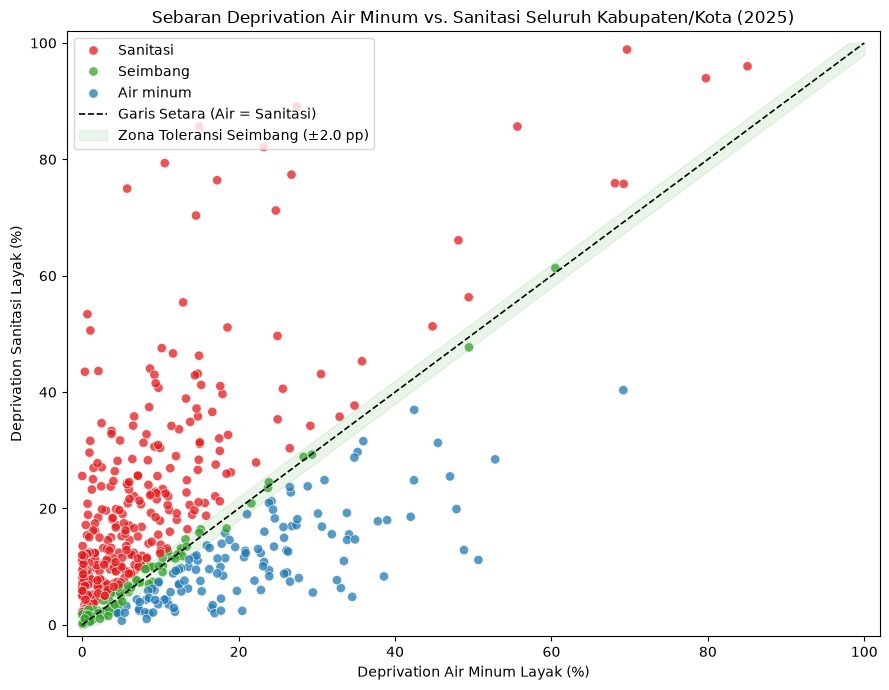

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

data_scatter = kab_data.dropna(
    subset=["deprivation_air", "deprivation_sanitasi"]
).copy()

palette_isu = {
    "Air minum": "#1f78b4",
    "Sanitasi": "#e31a1c",
    "Seimbang": "#33a02c",
    "Data tidak lengkap": "#999999"
}

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=data_scatter,
    x="deprivation_air",
    y="deprivation_sanitasi",
    hue="isu_dominan",
    palette=palette_isu,
    alpha=0.75,
    s=45
)

x_line = np.linspace(0, 100, 200)

plt.plot(
    x_line,
    x_line,
    linestyle="--",
    color="black",
    linewidth=1.2,
    label="Garis Setara (Air = Sanitasi)"
)

plt.fill_between(
    x_line,
    np.clip(x_line - AMBANG_SEIMBANG, 0, 100),
    np.clip(x_line + AMBANG_SEIMBANG, 0, 100),
    color="#33a02c",
    alpha=0.10,
    label=f"Zona Toleransi Seimbang (±{AMBANG_SEIMBANG} pp)"
)

plt.xlim(-2, 102)
plt.ylim(-2, 102)
plt.xlabel("Deprivation Air Minum Layak (%)")
plt.ylabel("Deprivation Sanitasi Layak (%)")
plt.title(
    "Sebaran Deprivation Air Minum vs. Sanitasi "
    "Seluruh Kabupaten/Kota (2025)"
)
plt.legend(loc="upper left")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "scatter_deprivation_nasional.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

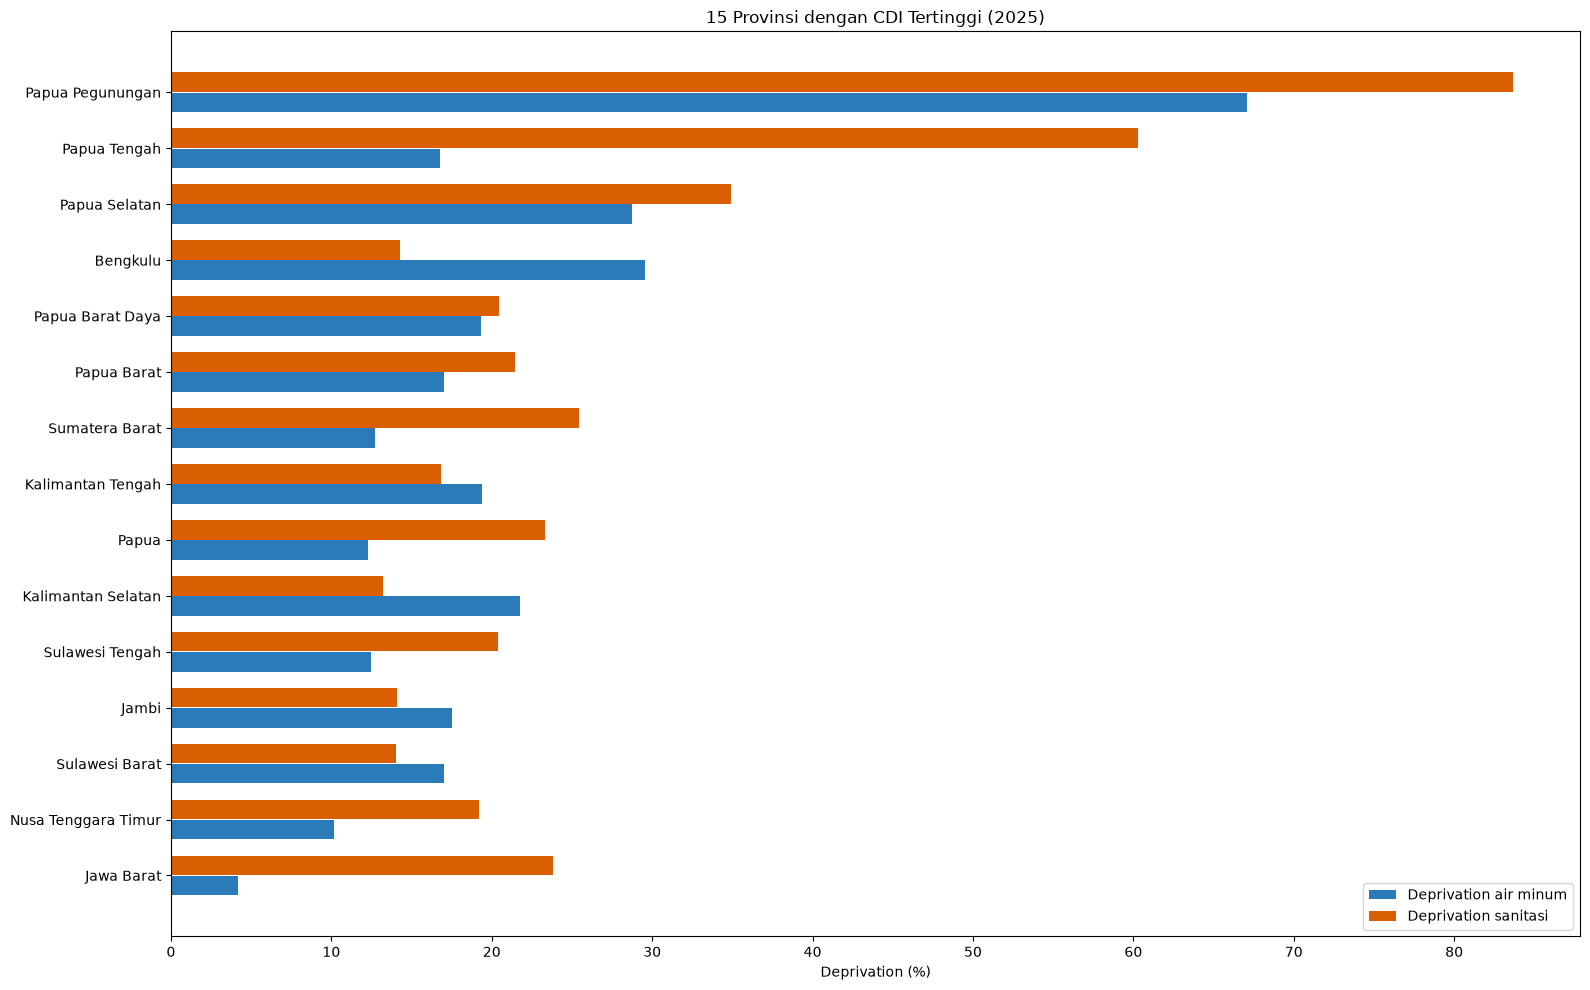

Grafik disimpan di: d:\Kuliah\Data Wrangling\Project\outputs\top15_provinsi_CDI_2025.png


In [54]:
import numpy as np
import matplotlib.pyplot as plt

# Ambil 15 provinsi dengan CDI tertinggi.
# Di grafik, nilai tertinggi akan tampil di bagian atas.
top15_prov = (
    prov_rank
    .head(15)
    .sort_values("CDI", ascending=True)
    .copy()
)

# Buat grafik
fig, ax = plt.subplots(figsize=(16, 10))

y_pos = np.arange(len(top15_prov))

ax.barh(
    y_pos - 0.18,
    top15_prov["deprivation_air"],
    height=0.35,
    label="Deprivation air minum",
    color="#2b7bba"
)

ax.barh(
    y_pos + 0.18,
    top15_prov["deprivation_sanitasi"],
    height=0.35,
    label="Deprivation sanitasi",
    color="#d95f02"
)

ax.set_yticks(y_pos)
ax.set_yticklabels(top15_prov["nama_provinsi_resmi"])
ax.set_xlabel("Deprivation (%)")
ax.set_title("15 Provinsi dengan CDI Tertinggi (2025)")
ax.legend(loc="lower right")

plt.tight_layout()

# Simpan grafik
file_grafik = OUTPUT_DIR / "top15_provinsi_CDI_2025.png"
plt.savefig(file_grafik, dpi=150, bbox_inches="tight")
plt.show()

print("Grafik disimpan di:", file_grafik)

In [55]:
if prov_rank.empty:
    raise ValueError(
        "Tidak ada provinsi dengan kedua indikator lengkap, sehingga CDI tidak dapat diperingkat."
    )

provinsi_terpilih = prov_rank.iloc[0]

kode_provinsi_terpilih = str(provinsi_terpilih["kode_provinsi"])
nama_provinsi_terpilih = provinsi_terpilih["nama_provinsi_resmi"]

print("Provinsi dengan CDI tertinggi:", nama_provinsi_terpilih)
print("Kode provinsi:", kode_provinsi_terpilih)
print("CDI:", round(float(provinsi_terpilih["CDI"]), 2))

Provinsi dengan CDI tertinggi: Papua Pegunungan
Kode provinsi: 95
CDI: 75.38


## 18. Analisis Kabupaten/Kota pada Provinsi Terpilih

Provinsi dengan CDI tertinggi dipilih berdasarkan data agregat provinsi. Pada bagian ini, kabupaten/kota di dalam provinsi tersebut diurutkan berdasarkan CDI.

Kabupaten/kota yang memiliki salah satu indikator hilang tetap ditampilkan, tetapi tidak masuk ke dalam peringkat CDI.

In [56]:
# Pilih kabupaten/kota berdasarkan kode provinsi terpilih.
kab_data["kode_provinsi"] = (
    kab_data["kode_provinsi"].astype("string").str.strip()
)

kab_prov_terpilih = kab_data[
    kab_data["kode_provinsi"] == str(kode_provinsi_terpilih).strip()
].copy()

if kab_prov_terpilih.empty:
    raise ValueError(
        f"Tidak ada data kabupaten/kota untuk {nama_provinsi_terpilih}."
    )

# Urutkan CDI dari tertinggi ke terendah.
kab_rank = kab_prov_terpilih.sort_values(
    "CDI", ascending=False, na_position="last"
).reset_index(drop=True)

# Buat peringkat hanya untuk wilayah yang CDI-nya tersedia.
kab_lengkap = kab_rank.dropna(subset=["CDI"]).copy()
kab_lengkap["peringkat_CDI"] = range(1, len(kab_lengkap) + 1)

kab_rank["peringkat_CDI"] = pd.NA

mask_cdi_tersedia = kab_rank["CDI"].notna()

kab_rank.loc[mask_cdi_tersedia, "peringkat_CDI"] = range(
    1,
    mask_cdi_tersedia.sum() + 1
)

print("Provinsi:", nama_provinsi_terpilih)
print("Jumlah kabupaten/kota:", len(kab_rank))
print("Jumlah CDI lengkap:", len(kab_lengkap))
print("Jumlah CDI tidak tersedia:", kab_rank["CDI"].isna().sum())

display(
    kab_rank[
        [
            "peringkat_CDI",
            "nama_kabupaten_resmi",
            "akses_air",
            "akses_sanitasi",
            "deprivation_air",
            "deprivation_sanitasi",
            "CDI",
            "isu_dominan"
        ]
    ]
)

Provinsi: Papua Pegunungan
Jumlah kabupaten/kota: 8
Jumlah CDI lengkap: 7
Jumlah CDI tidak tersedia: 1


,peringkat_CDI,nama_kabupaten_resmi,akses_air,akses_sanitasi,deprivation_air,deprivation_sanitasi,CDI,isu_dominan
0,1,Kabupaten Nduga,14.93,4.0,85.07,96.0,90.535,Sanitasi
1,2,Kabupaten Mamberamo Tengah,20.25,6.06,79.75,93.94,86.845,Sanitasi
2,3,Kabupaten Tolikara,30.34,1.13,69.66,98.87,84.265,Sanitasi
3,4,Kabupaten Yalimo,31.88,24.1,68.12,75.9,72.010,Sanitasi
4,5,Kabupaten Yahukimo,44.35,14.36,55.65,85.64,70.645,Sanitasi
5,6,Kabupaten Jayawijaya,50.58,43.7,49.42,56.3,52.860,Sanitasi
6,7,Kab Pegunungan Bintang,76.8,17.88,23.2,82.12,52.660,Sanitasi
7,<NA>,Kabupaten Lanny Jaya,<NA>,5.58,<NA>,94.42,NaN,Data tidak lengkap


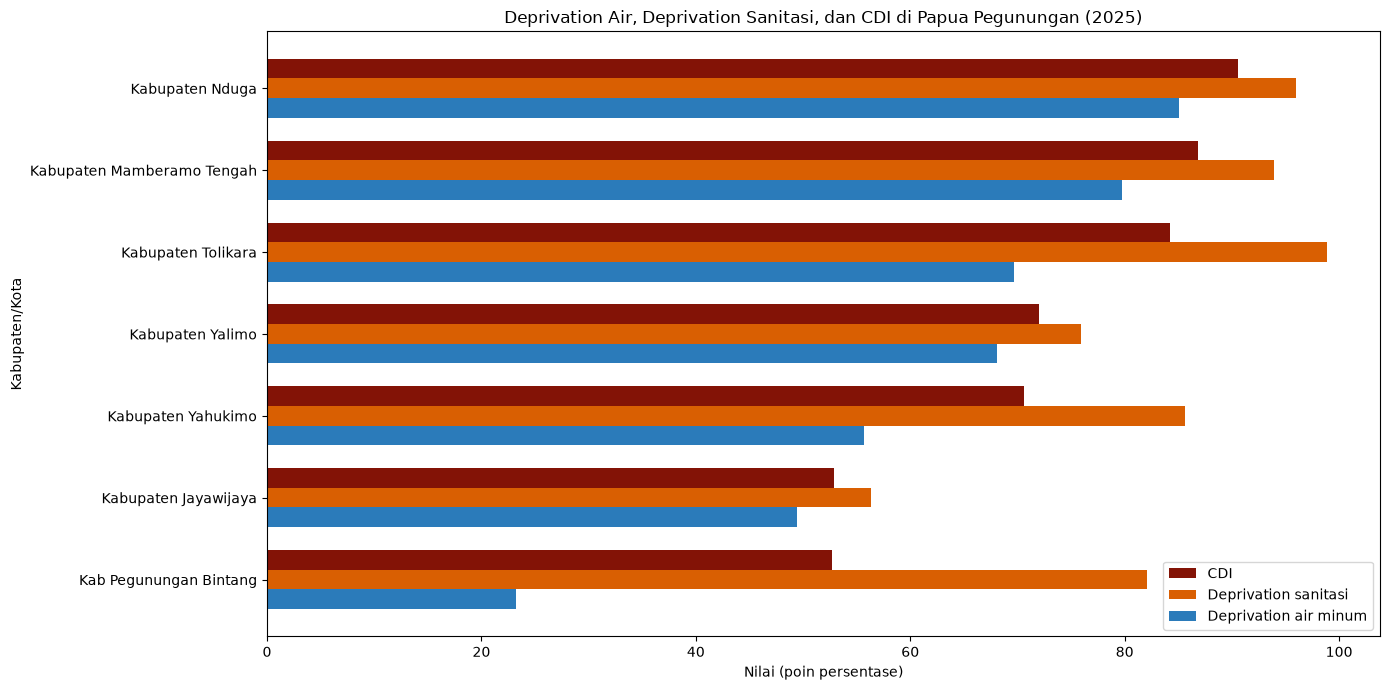

Grafik disimpan di: d:\Kuliah\Data Wrangling\Project\outputs\deprivation_dan_CDI_kabkota_terpilih.png


In [57]:
import numpy as np
import matplotlib.pyplot as plt

# Gunakan kabupaten/kota dengan CDI lengkap.
data_plot = (
    kab_rank
    .dropna(subset=["CDI"])
    .sort_values("CDI", ascending=True)
    .copy()
)

if data_plot.empty:
    raise ValueError("Tidak ada CDI lengkap untuk dibuatkan grafik.")

y = np.arange(len(data_plot))
tinggi_fig = max(7, 0.5 * len(data_plot))

fig, ax = plt.subplots(figsize=(14, tinggi_fig))

tinggi_batang = 0.24

ax.barh(
    y + tinggi_batang,
    data_plot["CDI"],
    height=tinggi_batang,
    label="CDI",
    color="#831306"
)

ax.barh(
    y,
    data_plot["deprivation_sanitasi"],
    height=tinggi_batang,
    label="Deprivation sanitasi",
    color="#d95f02"
)

ax.barh(
    y - tinggi_batang,
    data_plot["deprivation_air"],
    height=tinggi_batang,
    label="Deprivation air minum",
    color="#2b7bba"
)

ax.set_yticks(y)
ax.set_yticklabels(data_plot["nama_kabupaten_resmi"])
ax.set_xlabel("Nilai (poin persentase)")
ax.set_ylabel("Kabupaten/Kota")
ax.set_title(
    f"Deprivation Air, Deprivation Sanitasi, dan CDI "
    f"di {nama_provinsi_terpilih} (2025)"
)
ax.legend(loc="lower right")

plt.tight_layout()

file_grafik = OUTPUT_DIR / "deprivation_dan_CDI_kabkota_terpilih.png"
fig.savefig(file_grafik, dpi=150, bbox_inches="tight")
plt.show()

print("Grafik disimpan di:", file_grafik)

## 19. Analisis Korelasi Akses Air Minum dan Sanitasi

Analisis korelasi Pearson membandingkan hubungan antara persentase akses air minum layak dan sanitasi layak pada dua cakupan: seluruh kabupaten/kota di Indonesia dan kabupaten/kota di provinsi terpilih.

Setiap perhitungan hanya menggunakan wilayah yang memiliki kedua indikator. CDI tidak dimasukkan karena merupakan hasil perhitungan dari kedua indikator deprivation tersebut. Korelasi menggambarkan hubungan linear dalam data dan tidak membuktikan hubungan sebab-akibat.

Jumlah observasi provinsi terpilih jauh lebih sedikit daripada jumlah observasi nasional. Karena itu, nilai korelasi provinsi perlu ditafsirkan sebagai gambaran deskriptif, bukan kesimpulan yang mewakili seluruh wilayah.

In [58]:
kolom_korelasi = ["akses_air", "akses_sanitasi"]

# Seluruh kabupaten/kota di Indonesia
data_nasional = kab_data[kolom_korelasi].dropna()

# Kabupaten/kota pada provinsi terpilih
data_provinsi = kab_prov_terpilih[kolom_korelasi].dropna()

if len(data_nasional) < 3 or len(data_provinsi) < 3:
    raise ValueError(
        "Korelasi memerlukan setidaknya 3 wilayah dengan kedua indikator lengkap "
        "pada data nasional dan provinsi terpilih."
    )

corr_nasional = data_nasional.corr(method="pearson")
corr_provinsi = data_provinsi.corr(method="pearson")

print("Observasi nasional:", len(data_nasional))
print("Observasi provinsi terpilih:", len(data_provinsi))
print(
    "Korelasi Pearson nasional:",
    round(corr_nasional.loc["akses_air", "akses_sanitasi"], 3)
)
print(
    f"Korelasi Pearson {nama_provinsi_terpilih}:",
    round(corr_provinsi.loc["akses_air", "akses_sanitasi"], 3)
)

Observasi nasional: 512
Observasi provinsi terpilih: 7
Korelasi Pearson nasional: 0.542
Korelasi Pearson Papua Pegunungan: 0.5


Grafik disimpan di: d:\Kuliah\Data Wrangling\Project\outputs\korelasi_air_sanitasi.png


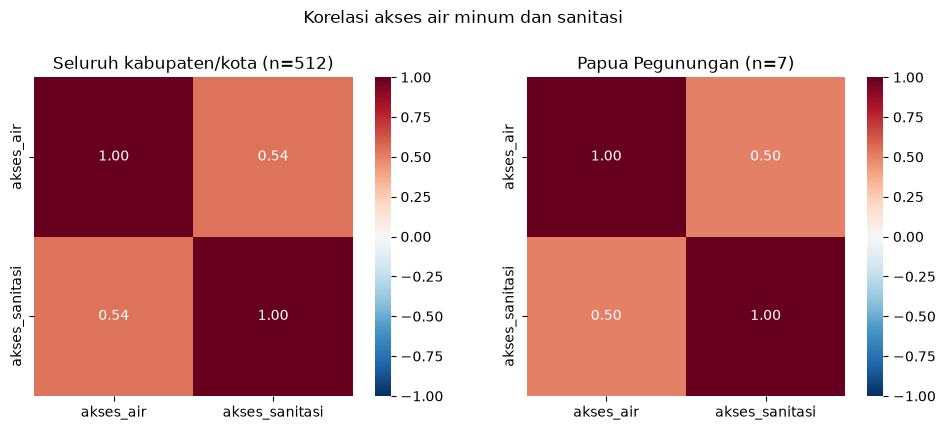

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(
    corr_nasional,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    square=True,
    ax=axes[0]
)
axes[0].set_title(f"Seluruh kabupaten/kota (n={len(data_nasional)})")

sns.heatmap(
    corr_provinsi,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    square=True,
    ax=axes[1]
)
axes[1].set_title(
    f"{nama_provinsi_terpilih} (n={len(data_provinsi)})"
)

fig.suptitle("Korelasi akses air minum dan sanitasi", y=1.03)
plt.tight_layout()
file_grafik = OUTPUT_DIR / "korelasi_air_sanitasi.png"
plt.savefig(file_grafik, dpi=150, bbox_inches="tight")
print("Grafik disimpan di:", file_grafik)
plt.show()

## 20. Clustering Kabupaten/Kota dengan K-Means

K-Means digunakan secara eksploratif untuk mengelompokkan kabupaten/kota berdasarkan deprivation air minum dan sanitasi. Analisis menggunakan seluruh kabupaten/kota dengan kedua indikator lengkap agar jumlah observasi memadai.

Sebelum clustering, kedua fitur distandardisasi karena K-Means menggunakan jarak dan sensitif terhadap skala. Jumlah klaster dibandingkan menggunakan silhouette score. Nilai outlier tetap dipertahankan dan hasil clustering ditafsirkan secara hati-hati.

In [60]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

fitur_cluster = ["deprivation_air", "deprivation_sanitasi"]

cluster_data = kab_data.dropna(subset=fitur_cluster).copy()

if len(cluster_data) < 4:
    raise ValueError(
        "Jumlah wilayah lengkap terlalu sedikit untuk evaluasi clustering."
    )

X = cluster_data[fitur_cluster]

# Standardisasi fitur agar keduanya berada pada skala yang sebanding.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Coba jumlah klaster k=2 sampai k=6, selama jumlah data memungkinkan.
hasil_silhouette = []

k_maksimum = min(6, len(cluster_data) - 1)

for k in range(2, k_maksimum + 1):
    model = KMeans(
        n_clusters=k,
        random_state=7,
        n_init=10
    )

    label = model.fit_predict(X_scaled)

    skor = silhouette_score(X_scaled, label)
    hasil_silhouette.append({
        "jumlah_klaster": k,
        "silhouette": skor
    })

silhouette_df = pd.DataFrame(hasil_silhouette)
silhouette_df.to_csv(
    OUTPUT_DIR / "evaluasi_jumlah_klaster.csv",
    index=False,
)

display(silhouette_df.round(3))

,jumlah_klaster,silhouette
0,2,0.554
1,3,0.489
2,4,0.500
3,5,0.489
4,6,0.464


In [61]:
k_terbaik = int(
    silhouette_df.loc[
        silhouette_df["silhouette"].idxmax(),
        "jumlah_klaster"
    ]
)

model_terbaik = KMeans(
    n_clusters=k_terbaik,
    random_state=7,
    n_init=10
)

cluster_data["cluster"] = model_terbaik.fit_predict(X_scaled)

print("Jumlah klaster terpilih:", k_terbaik)
print(
    "Silhouette score:",
    round(
        silhouette_df.loc[
            silhouette_df["jumlah_klaster"] == k_terbaik,
            "silhouette"
        ].iloc[0],
        3
    )
)

# Rata-rata deprivation untuk membantu menafsirkan tiap klaster.
ringkasan_cluster = (
    cluster_data
    .groupby("cluster")[fitur_cluster + ["CDI"]]
    .mean()
    .round(2)
)

ringkasan_cluster.to_csv(
    OUTPUT_DIR / "ringkasan_klaster.csv"
)
display(ringkasan_cluster)

Jumlah klaster terpilih: 2
Silhouette score: 0.554


,deprivation_air,deprivation_sanitasi,CDI
cluster,,,
0,29.03,37.99,33.51
1,6.92,11.35,9.14


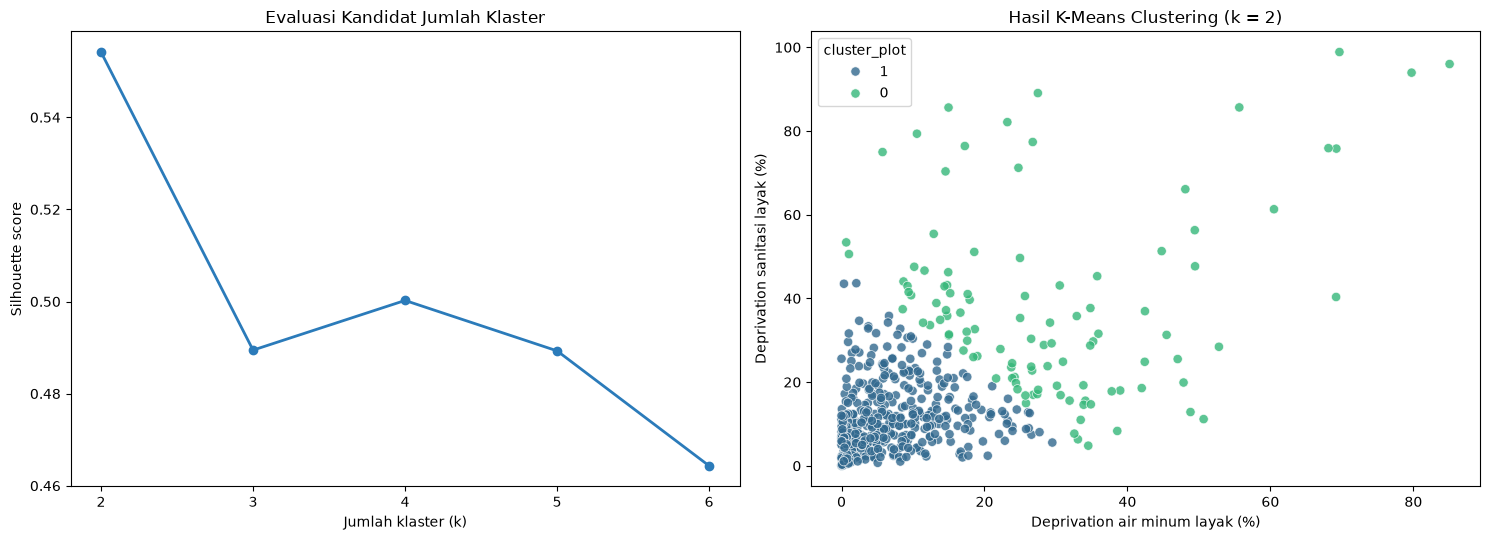

Grafik clustering disimpan di: d:\Kuliah\Data Wrangling\Project\outputs\clustering_kmeans_deprivation.png


In [62]:
# Grafik evaluasi silhouette dan sebaran hasil K-Means
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Grafik evaluasi jumlah klaster
axes[0].plot(
    silhouette_df["jumlah_klaster"],
    silhouette_df["silhouette"],
    marker="o",
    linewidth=2,
    color="#2b7bba"
)
axes[0].set_xticks(silhouette_df["jumlah_klaster"])
axes[0].set_xlabel("Jumlah klaster (k)")
axes[0].set_ylabel("Silhouette score")
axes[0].set_title("Evaluasi Kandidat Jumlah Klaster")

# Jadikan label klaster kategori agar legenda menampilkan setiap klaster.
cluster_data["cluster_plot"] = cluster_data["cluster"].astype(str)

sns.scatterplot(
    data=cluster_data,
    x="deprivation_air",
    y="deprivation_sanitasi",
    hue="cluster_plot",
    palette="viridis",
    alpha=0.8,
    s=45,
    ax=axes[1]
)
axes[1].set_xlabel("Deprivation air minum layak (%)")
axes[1].set_ylabel("Deprivation sanitasi layak (%)")
axes[1].set_title(f"Hasil K-Means Clustering (k = {k_terbaik})")

plt.tight_layout()

file_grafik_cluster = OUTPUT_DIR / "clustering_kmeans_deprivation.png"
plt.savefig(file_grafik_cluster, dpi=150, bbox_inches="tight")
plt.show()

print("Grafik clustering disimpan di:", file_grafik_cluster)

In [63]:
cluster_prov_terpilih = cluster_data[
    cluster_data["kode_provinsi"].astype("string").str.strip()
    == str(kode_provinsi_terpilih).strip()
].copy()

display(
    cluster_prov_terpilih[
        [
            "nama_kabupaten_resmi",
            "deprivation_air",
            "deprivation_sanitasi",
            "CDI",
            "cluster"
        ]
    ].sort_values("CDI", ascending=False)
)

,nama_kabupaten_resmi,deprivation_air,deprivation_sanitasi,CDI,cluster
263,Kabupaten Nduga,85.07,96.0,90.535,0
225,Kabupaten Mamberamo Tengah,79.75,93.94,86.845,0
401,Kabupaten Tolikara,69.66,98.87,84.265,0
415,Kabupaten Yalimo,68.12,75.9,72.010,0
414,Kabupaten Yahukimo,55.65,85.64,70.645,0
126,Kabupaten Jayawijaya,49.42,56.3,52.860,0
295,Kab Pegunungan Bintang,23.2,82.12,52.660,0


## 21. Menggabungkan Hasil Analisis dengan Batas Wilayah

Data kabupaten/kota pada provinsi terpilih digabungkan dengan GeoJSON menggunakan kode kabupaten/kota. Pencocokan berdasarkan kode lebih konsisten daripada berdasarkan nama.

Sebelum peta dibuat, notebook memeriksa keunikan kode dan menampilkan wilayah yang tidak mendapatkan geometri.

In [64]:
# Pastikan kode join berupa teks dengan spasi luar dibuang.
batas_peta = batas_kabkota.copy()
batas_peta["_kode_kab"] = (
    batas_peta["_kode_kab"].astype("string").str.strip()
)

data_peta = kab_prov_terpilih.copy()
data_peta["kode_kabupaten"] = (
    data_peta["kode_kabupaten"].astype("string").str.strip()
)

# Pastikan tidak ada kode ganda pada kedua tabel.
if batas_peta["_kode_kab"].duplicated().any():
    raise ValueError("Ada kode kabupaten/kota ganda pada geometri hasil dissolve.")

if data_peta["kode_kabupaten"].duplicated().any():
    raise ValueError("Ada kode kabupaten/kota ganda pada data indikator.")

peta_gdf = batas_peta.merge(
    data_peta,
    left_on="_kode_kab",
    right_on="kode_kabupaten",
    how="inner",
    validate="one_to_one"
)

kode_data_tanpa_geometri = (
    set(data_peta["kode_kabupaten"].dropna())
    - set(peta_gdf["kode_kabupaten"].dropna())
)

print("Wilayah di provinsi terpilih:", len(data_peta))
print("Wilayah yang berhasil dipetakan:", len(peta_gdf))
print("Kode data tanpa geometri:", sorted(kode_data_tanpa_geometri))

if peta_gdf.empty:
    raise ValueError("Join data dan geometri kosong. Periksa kembali format kode.")

Wilayah di provinsi terpilih: 8
Wilayah yang berhasil dipetakan: 8
Kode data tanpa geometri: []


## 22. Peta Combined Deprivation Index

Warna peta menunjukkan CDI. Nilai yang lebih tinggi menunjukkan deprivation gabungan yang lebih tinggi. Wilayah dengan CDI tidak tersedia ditampilkan dengan warna abu-abu.

In [65]:
import folium
from branca.colormap import LinearColormap
import numpy as np

# Siapkan pusat tampilan berdasarkan batas wilayah terpilih.
minx, miny, maxx, maxy = peta_gdf.total_bounds
pusat_peta = [(miny + maxy) / 2, (minx + maxx) / 2]

nilai_cdi = peta_gdf["CDI"].dropna()

if nilai_cdi.empty:
    raise ValueError("Tidak ada nilai CDI untuk ditampilkan pada peta.")

vmin = float(nilai_cdi.min())
vmax = float(nilai_cdi.max())

# Hindari rentang warna nol jika semua CDI sama.
if vmin == vmax:
    vmax = vmin + 1

skala_cdi = LinearColormap(
    colors=["#ffffb2", "#fecc5c", "#fd8d3c", "#e31a1c"],
    vmin=vmin,
    vmax=vmax,
    caption="Combined Deprivation Index (CDI)"
)

def gaya_cdi(feature):
    nilai = feature["properties"].get("CDI")

    if nilai is None or pd.isna(nilai):
        warna = "#bdbdbd"
    else:
        warna = skala_cdi(float(nilai))

    return {
        "fillColor": warna,
        "color": "#555555",
        "weight": 0.6,
        "fillOpacity": 0.8
    }

kolom_tooltip = [
    "nama_kabupaten_resmi",
    "akses_air",
    "akses_sanitasi",
    "CDI",
    "isu_dominan"
]

alias_tooltip = [
    "Kabupaten/Kota",
    "Akses air minum (%)",
    "Akses sanitasi (%)",
    "CDI",
    "Isu dominan"
]

peta_cdi = folium.Map(
    location=pusat_peta,
    zoom_start=7,
    tiles=None
)

folium.GeoJson(
    peta_gdf,
    name="CDI",
    style_function=gaya_cdi,
    tooltip=folium.GeoJsonTooltip(
        fields=kolom_tooltip,
        aliases=alias_tooltip,
        localize=True
    )
).add_to(peta_cdi)

skala_cdi.add_to(peta_cdi)
peta_cdi.fit_bounds([[miny, minx], [maxy, maxx]])

file_peta_cdi = OUTPUT_DIR / (
    f"peta_CDI_{kode_provinsi_terpilih}.html"
)
peta_cdi.save(file_peta_cdi)

print("Peta CDI disimpan di:", file_peta_cdi)   

Peta CDI disimpan di: d:\Kuliah\Data Wrangling\Project\outputs\peta_CDI_95.html


## 23. Peta Kategori Isu Dominan

Peta kategori menampilkan indikator yang memiliki deprivation lebih besar. Wilayah dengan nilai salah satu indikator yang hilang diberi kategori “Data tidak lengkap”.

In [66]:
warna_kategori = {
    "Air minum": "#2b83ba",
    "Sanitasi": "#d7191c",
    "Seimbang": "#fdae61",
    "Data tidak lengkap": "#bdbdbd"
}

def gaya_kategori(feature):
    kategori = feature["properties"].get("isu_dominan")
    return {
        "fillColor": warna_kategori.get(kategori, "#bdbdbd"),
        "color": "#555555",
        "weight": 0.6,
        "fillOpacity": 0.8
    }

peta_kategori = folium.Map(
    location=pusat_peta,
    zoom_start=7,
    tiles=None
)

folium.GeoJson(
    peta_gdf,
    name="Isu dominan",
    style_function=gaya_kategori,
    tooltip=folium.GeoJsonTooltip(
        fields=kolom_tooltip,
        aliases=alias_tooltip,
        localize=True
    )
).add_to(peta_kategori)

legenda = """
<div style="
    position: fixed;
    bottom: 30px;
    left: 30px;
    z-index: 9999;
    background: white;
    padding: 10px;
    border: 1px solid #999;
    font-size: 14px;
">
<b>Isu dominan</b><br>
<span style="color:#2b83ba;">■</span> Air minum<br>
<span style="color:#d7191c;">■</span> Sanitasi<br>
<span style="color:#fdae61;">■</span> Seimbang<br>
<span style="color:#bdbdbd;">■</span> Data tidak lengkap
</div>
"""

peta_kategori.get_root().html.add_child(folium.Element(legenda))
peta_kategori.fit_bounds([[miny, minx], [maxy, maxx]])

file_peta_kategori = OUTPUT_DIR / (
    f"peta_kategori_dominan_{kode_provinsi_terpilih}.html"
)
peta_kategori.save(file_peta_kategori)

print("Peta kategori disimpan di:", file_peta_kategori)

Peta kategori disimpan di: d:\Kuliah\Data Wrangling\Project\outputs\peta_kategori_dominan_95.html


## 24. Ekspor Hasil Analisis

Tabel hasil disimpan dalam format CSV di folder `outputs/`. Data sumber tidak ditimpa. File keluaran meliputi data kabupaten/kota yang sudah dibersihkan, ranking provinsi, analisis kabupaten/kota di provinsi terpilih, hasil clustering, dan data yang digunakan untuk peta.

In [67]:
# Tambahkan label klaster pada data kabupaten/kota.
label_cluster = cluster_data[
    ["kode_kabupaten", "cluster"]
].copy()

label_cluster["kode_kabupaten"] = (
    label_cluster["kode_kabupaten"].astype("string").str.strip()
)

kab_export = kab_data.copy()
kab_export["kode_kabupaten"] = (
    kab_export["kode_kabupaten"].astype("string").str.strip()
)

kab_export = kab_export.merge(
    label_cluster,
    on="kode_kabupaten",
    how="left",
    validate="one_to_one"
)

# Simpan tabel analisis.
kab_export.to_csv(
    OUTPUT_DIR / "clean_data_kabupaten_kota.csv",
    index=False,
    encoding="utf-8-sig"
)

prov_rank.to_csv(
    OUTPUT_DIR / "ranking_CDI_provinsi.csv",
    index=False,
    encoding="utf-8-sig"
)

kab_rank.to_csv(
    OUTPUT_DIR / f"analisis_kabupaten_kota_{kode_provinsi_terpilih}.csv",
    index=False,
    encoding="utf-8-sig"
)

# Simpan tabel yang digunakan untuk peta, tanpa geometri besar.
peta_gdf.drop(columns="geometry").to_csv(
    OUTPUT_DIR / f"data_peta_{kode_provinsi_terpilih}.csv",
    index=False,
    encoding="utf-8-sig"
)

print("File keluaran tersimpan di:", OUTPUT_DIR.resolve())

File keluaran tersimpan di: D:\Kuliah\Data Wrangling\Project\outputs


In [68]:
kab_lengkap = kab_rank.dropna(subset=["CDI"])

print("TAHUN DATA: 2025")
print("Provinsi dengan CDI tertinggi:", nama_provinsi_terpilih)
print("CDI provinsi:", round(float(provinsi_terpilih["CDI"]), 2))
print("Jumlah kabupaten/kota di provinsi:", len(kab_rank))
print("Kabupaten/kota dengan CDI lengkap:", len(kab_lengkap))
print("Kabupaten/kota dengan CDI tidak tersedia:",
      kab_rank["CDI"].isna().sum())

if not kab_lengkap.empty:
    tertinggi = kab_lengkap.loc[kab_lengkap["CDI"].idxmax()]
    terendah = kab_lengkap.loc[kab_lengkap["CDI"].idxmin()]

    print(
        "CDI kabupaten/kota tertinggi:",
        tertinggi["nama_kabupaten_resmi"],
        "—",
        round(float(tertinggi["CDI"]), 2)
    )

    print(
        "CDI kabupaten/kota terendah:",
        terendah["nama_kabupaten_resmi"],
        "—",
        round(float(terendah["CDI"]), 2)
    )

print("\nKategori isu dominan pada provinsi terpilih:")
display(kab_rank["isu_dominan"].value_counts().to_frame("jumlah_wilayah"))

TAHUN DATA: 2025
Provinsi dengan CDI tertinggi: Papua Pegunungan
CDI provinsi: 75.38
Jumlah kabupaten/kota di provinsi: 8
Kabupaten/kota dengan CDI lengkap: 7
Kabupaten/kota dengan CDI tidak tersedia: 1
CDI kabupaten/kota tertinggi: Kabupaten Nduga — 90.53
CDI kabupaten/kota terendah: Kab Pegunungan Bintang — 52.66

Kategori isu dominan pada provinsi terpilih:


,jumlah_wilayah
isu_dominan,
Sanitasi,7
Data tidak lengkap,1


## 25. Kesimpulan

Berdasarkan data tahun 2025, Papua Pegunungan memiliki CDI provinsi tertinggi sebesar **75,38**. Nilai tersebut menunjukkan bahwa rata-rata deprivation akses air minum layak dan sanitasi layak di provinsi tersebut lebih tinggi dibandingkan provinsi lain dalam analisis ini.

Pada tingkat kabupaten/kota di Papua Pegunungan, Kabupaten Nduga memiliki CDI tertinggi, yaitu **90,53**. Kabupaten Pegunungan Bintang memiliki CDI terendah di antara wilayah dengan data lengkap, yaitu **52,66**. Satu kabupaten/kota tidak dapat diberi CDI karena salah satu indikatornya kosong.

Hasil ini bersifat deskriptif dan mengikuti ketersediaan data serta definisi CDI yang digunakan dalam proyek. Peringkat tidak menjelaskan penyebab perbedaan akses dan tidak menggantikan ukuran resmi kesejahteraan.

## 26. Keterbatasan analisis

1. CDI memberi bobot sama pada deprivation air minum dan sanitasi. CDI bukan ukuran resmi kemiskinan multidimensi.
2. Nilai indikator yang kosong tidak dianggap nol. Jika salah satu indikator hilang, CDI tidak dihitung.
3. Ranking provinsi menggunakan data agregat provinsi dari file sumber, bukan rata-rata sederhana kabupaten/kota.
4. Kategori “Seimbang” dipengaruhi ambang toleransi yang digunakan.
5. Deteksi outlier dengan IQR hanya menandai nilai untuk pemeriksaan; outlier tidak otomatis dihapus.
6. Korelasi dan peta bersifat deskriptif, tidak membuktikan hubungan sebab-akibat.
7. Clustering K-Means bersifat eksploratif. Hasilnya sensitif terhadap data, skala, outlier, dan jumlah klaster.
8. Peta menunjukkan nilai pada tingkat wilayah, bukan variasi di dalam wilayah.
9. Beberapa fitur GeoJSON tidak dapat dicocokkan dengan kode kabupaten/kota dan dikecualikan dari layer analisis. Pengecualian tersebut telah diperiksa dan dilaporkan.
10. Sumber data memiliki tahun dan edisi tertentu. Cantumkan judul file, instansi, periode data, path atau tautan sumber, tanggal akses bila tersedia, serta atribusi BIG sesuai metadata.